# Assignment 5: Attention-Based Text Classification

**Course:** AAI 6640 — Applied Deep Learning
**Module:** Week 12 (12.7)
**Author:** Muhammad Obaidullah
**Dataset:** IMDB movie reviews (Keras)
**Task:** Binary sentiment classification: positive (1) or negative (0)

## Overview

**Objective:** classify IMDB reviews as positive or negative with two bidirectional-LSTM models that differ in one respect only, how the sequence of LSTM hidden states is summarized into one vector:

| Model | Summary of the BiLSTM sequence |
|---|---|
| Final-state BiLSTM (baseline) | Concatenation of the forward and backward **final** hidden states |
| Attention-based BiLSTM | **Additive attention pooling**: a learned weighted sum of **all** hidden states |

**Approach:** load → explore → split 80 / 20 → pad to 200 → train baseline → implement attention layer → train attention model → analyze attention weights → select on validation → evaluate once on test → reflect.

**Conventions:** one seed (`SEED = 42`) governs the split, weight initialization, and batch shuffling. The original 25,000-review test set is touched once, in Step 7. "Best validation accuracy" always means the highest validation accuracy over the epochs of a run; early stopping restores the weights from that epoch, so the reported number and the evaluated model match.

## Setup

All imports, constants, and display settings. Every fixed setting of the comparison is a named constant here, so both models read the same values.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before TensorFlow loads; hides C++ notices

import textwrap
import time
from dataclasses import dataclass
from html import escape

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import HTML, display
from keras import layers
from keras.datasets import imdb  # same loader as tensorflow.keras.datasets.imdb
from keras.utils import pad_sequences
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Data
SEED = 42
VOCAB_SIZE = 10_000
MAX_LEN = 200
VAL_FRACTION = 0.20

# Architecture (shared by both models except the summary step)
EMBED_DIM = 128
LSTM_UNITS = 64  # per direction, so hidden states are 2 × 64 = 128-dimensional
DENSE_UNITS = 64
ATTENTION_DIM = 64

# Training (identical for both models)
LEARNING_RATE = 1e-3  # Adam's default, stated explicitly
BATCH_SIZE = 64
MAX_EPOCHS = 10
PATIENCE = 3  # early-stopping patience on validation accuracy
THRESHOLD = 0.5

keras.utils.set_random_seed(SEED)  # Python, NumPy, and TensorFlow RNGs
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")  # hides tf.function retracing notices; they concern speed, not results

set_matplotlib_formats("retina")
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 4)

print(
    f"TensorFlow {tf.__version__} | Keras {keras.__version__} | "
    f"scikit-learn {sklearn.__version__} | NumPy {np.__version__} | "
    f"pandas {pd.__version__}"
)
gpus = tf.config.list_physical_devices("GPU")
gpu_names = [tf.config.experimental.get_device_details(g).get("device_name", g.name) for g in gpus]
print(f"GPU: {', '.join(gpu_names) or 'none (CPU)'}")


def create_device_quietly() -> None:
    """Run TensorFlow's first op (which creates the device) with C-level stderr muted.

    TensorFlow logs device creation to stderr before its logging is configured, so
    TF_CPP_MIN_LOG_LEVEL cannot hide it. Python exceptions are unaffected.
    """
    saved_stderr = os.dup(2)
    try:
        with open(os.devnull, "w") as devnull:
            os.dup2(devnull.fileno(), 2)
            tf.zeros(1)
    finally:
        os.dup2(saved_stderr, 2)
        os.close(saved_stderr)


create_device_quietly()

TensorFlow 2.20.0 | Keras 3.15.1 | scikit-learn 1.9.1 | NumPy 2.5.4 | pandas 3.1.1
GPU: NVIDIA L40S


## Step 1 — Prepare and explore the data

`imdb.load_data` returns each review as a list of word indices, where index $k + 3$ is the $k$-th most frequent word in the corpus. Three indices are reserved: **0** for padding, **1** marks the start of every review, and **2** replaces any word outside the 10,000 most frequent (out-of-vocabulary, OOV).

In [2]:
(x_train_full, y_train_full), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
word_index = imdb.get_word_index()

print(f"Training reviews: {len(x_train_full):,}")
print(f"Test reviews:     {len(x_test_raw):,}")

Training reviews: 25,000
Test reviews:     25,000


### Class balance

In [3]:
LABELS = {0: "negative", 1: "positive"}


def class_balance(labels_by_split: dict[str, np.ndarray]) -> pd.DataFrame:
    """Review counts per class, with the positive share, for each split."""
    rows = {}
    for name, labels in labels_by_split.items():
        n_pos = int(labels.sum())
        rows[name] = {
            "Reviews": len(labels),
            "Negative (0)": len(labels) - n_pos,
            "Positive (1)": n_pos,
            "Positive (%)": 100 * n_pos / len(labels),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


class_balance({"Training": y_train_full, "Test": y_test})

,Reviews,Negative (0),Positive (1),Positive (%)
Training,25000,12500,12500,50.0
Test,25000,12500,12500,50.0


### Review lengths

Lengths count tokens, including the start token, before any padding or truncation.

In [4]:
def review_lengths(reviews) -> np.ndarray:
    """Number of tokens in each review."""
    return np.array([len(review) for review in reviews])


train_lengths, test_lengths = review_lengths(x_train_full), review_lengths(x_test_raw)

percentiles = [0.25, 0.5, 0.75, 0.9, 0.99]
length_stats = pd.DataFrame(
    {
        "Training": pd.Series(train_lengths).describe(percentiles=percentiles),
        "Test": pd.Series(test_lengths).describe(percentiles=percentiles),
    }
).T.drop(columns="count")
length_stats[f"> {MAX_LEN} tokens (%)"] = [
    100 * np.mean(train_lengths > MAX_LEN),
    100 * np.mean(test_lengths > MAX_LEN),
]
length_stats.round(2)

,mean,std,min,25%,50%,75%,90%,99%,max,> 200 tokens (%)
Training,238.71,176.50,11.0,130.0,178.0,291.0,467.0,926.00,2494.0,42.71
Test,230.80,169.16,7.0,128.0,174.0,280.0,446.1,902.01,2315.0,41.07


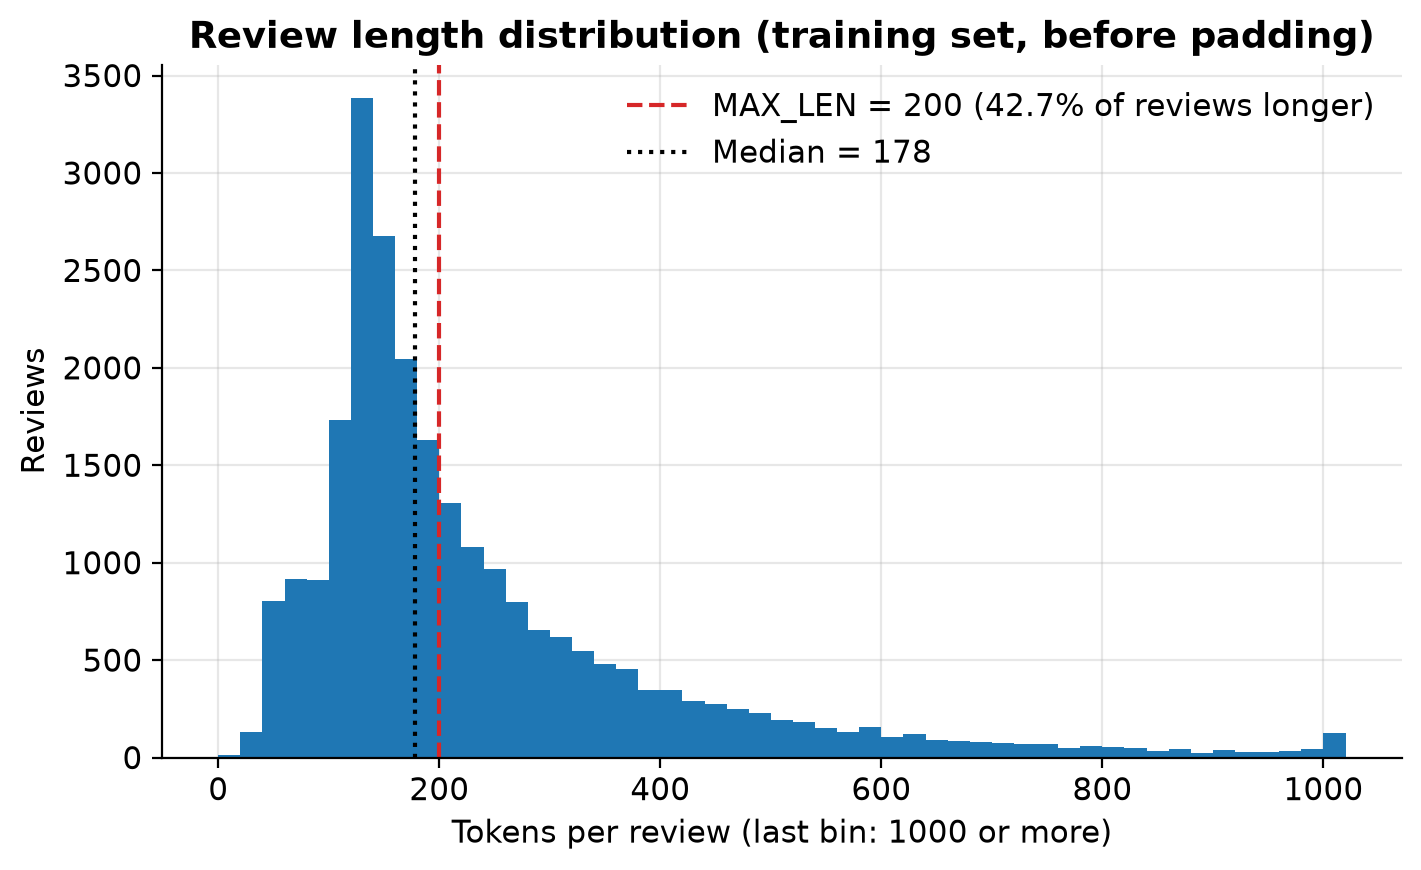

In [5]:
CLIP = 1000  # reviews at or above this length share the last bin
share_long = np.mean(train_lengths > MAX_LEN)

fig, ax = plt.subplots()
ax.hist(np.minimum(train_lengths, CLIP), bins=np.arange(0, CLIP + 21, 20))
ax.axvline(
    MAX_LEN, color="C3", ls="--", label=f"MAX_LEN = {MAX_LEN} ({share_long:.1%} of reviews longer)"
)
ax.axvline(
    np.median(train_lengths), color="k", ls=":", label=f"Median = {np.median(train_lengths):.0f}"
)
ax.set(
    title="Review length distribution (training set, before padding)",
    xlabel=f"Tokens per review (last bin: {CLIP} or more)",
    ylabel="Reviews",
)
ax.legend()
plt.show()

### Decoded examples

`decode` inverts the index offset. One negative and one positive review that fit within 200 tokens, and one review just over 200 tokens, with a marker where `truncating="post"` will cut it.

In [6]:
INDEX_FROM = 3  # load_data shifts word ranks by 3 to free 0 (pad), 1 (start), 2 (OOV)
SPECIAL_TOKENS = {0: "<pad>", 1: "<start>", 2: "<oov>"}
index_to_word = {rank + INDEX_FROM: word for word, rank in word_index.items()} | SPECIAL_TOKENS


def decode(ids) -> list[str]:
    """Token indices → words, dropping padding (index 0)."""
    return [index_to_word.get(int(i), "<oov>") for i in ids if i != 0]


def show_review(i: int) -> None:
    """Print one training review with its label, marking the truncation point if any."""
    words = decode(x_train_full[i])
    if len(words) > MAX_LEN:
        marker = f"‖ TRUNCATED HERE ({len(words) - MAX_LEN} tokens dropped) ‖"
        words = words[:MAX_LEN] + [marker] + words[MAX_LEN:]
    label = int(y_train_full[i])
    print(f"Review #{i} | label {label} ({LABELS[label]}) | {len(x_train_full[i])} tokens")
    print(textwrap.fill(" ".join(words), width=110), end="\n\n")


kept_whole = train_lengths <= MAX_LEN
example_ids = [
    int(np.flatnonzero((y_train_full == 0) & kept_whole)[0]),
    int(np.flatnonzero((y_train_full == 1) & kept_whole)[0]),
    int(np.flatnonzero((train_lengths > MAX_LEN) & (train_lengths <= MAX_LEN + 60))[0]),
]
for i in example_ids:
    show_review(i)

Review #1 | label 0 (negative) | 189 tokens
<start> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible
movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the
plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is
the end showdown with the cop and how he worked out who the killer is it's just so damn terribly written the
clothes are sickening and funny in equal <oov> the hair is big lots of boobs <oov> men wear those cut <oov>
shirts that show off their <oov> sickening that men actually wore them and the music is just <oov> trash that
plays over and over again in almost every scene there is trashy music boobs and <oov> taking away bodies and
the gym still doesn't close for <oov> all joking aside this is a truly bad film whose only charm is to look
back on the disaster that was the 80's and have a good old laugh at how bad every

### Split and pad

The original training set is split 80 / 20 into training and validation, stratified by label so both keep the 50 / 50 class balance. The original test set stays aside until Step 7.

Every review is then padded or truncated to 200 tokens with `padding="post"` and `truncating="post"`: short reviews get zeros appended at the end, and long reviews keep their **first** 200 tokens. Post-padding places all real tokens before all padding, which `mask_zero=True` turns into a mask of the form `[True, …, True, False, …, False]`. The check below confirms that index 0 never occurs as a real token, so the mask cannot hide a word.

In [7]:
min_token = min(min(review) for review in np.concatenate([x_train_full, x_test_raw]))
print(f"Smallest token index in any review: {min_token} → index 0 marks padding only")

x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=VAL_FRACTION,
    stratify=y_train_full,
    random_state=SEED,
)


def pad(reviews) -> np.ndarray:
    """Pad or truncate every review to MAX_LEN tokens, both at the end."""
    return pad_sequences(reviews, maxlen=MAX_LEN, padding="post", truncating="post", value=0)


X_train, X_val, X_test = pad(x_train_raw), pad(x_val_raw), pad(x_test_raw)
val_raw_lengths, test_raw_lengths = review_lengths(x_val_raw), review_lengths(x_test_raw)

Smallest token index in any review: 1 → index 0 marks padding only


In [8]:
def split_profile(raw_reviews, padded: np.ndarray, labels: np.ndarray) -> dict:
    """Size, balance, and truncation / padding statistics of one split."""
    raw = review_lengths(raw_reviews)
    return {
        "Reviews": len(labels),
        "Positive (%)": 100 * labels.mean(),
        "Truncated (%)": 100 * np.mean(raw > MAX_LEN),
        "Padded (%)": 100 * np.mean(raw < MAX_LEN),
        "Tokens dropped (%)": 100 * np.maximum(raw - MAX_LEN, 0).sum() / raw.sum(),
        "Mean real tokens kept": (padded != 0).sum(axis=1).mean(),
        "Padded array shape": str(padded.shape),
    }


pd.DataFrame.from_dict(
    {
        "Training": split_profile(x_train_raw, X_train, y_train),
        "Validation": split_profile(x_val_raw, X_val, y_val),
        "Test (held out)": split_profile(x_test_raw, X_test, y_test),
    },
    orient="index",
).round(2)

,Reviews,Positive (%),Truncated (%),Padded (%),Tokens dropped (%),Mean real tokens kept,Padded array shape
Training,20000,50.0,42.73,56.96,32.48,161.03,"(20000, 200)"
Validation,5000,50.0,42.62,57.04,32.69,161.27,"(5000, 200)"
Test (held out),25000,50.0,41.07,58.68,30.98,159.30,"(25000, 200)"


In [9]:
short = int(np.argmin(review_lengths(x_train_raw)))
print("Shortest training review after padding (first 12 and last 12 positions):")
print(X_train[short][:12], "…", X_train[short][-12:])

Shortest training review after padding (first 12 and last 12 positions):
[  1  14  20   9 394  21  12  47  49  52 302   0] … [0 0 0 0 0 0 0 0 0 0 0 0]


### Why these preprocessing choices

**Why sequences need a consistent length for batch training.** A mini-batch is a single dense tensor of shape `(batch_size, T)`, and every layer operates on the whole tensor at once: the embedding lookup, the LSTM's matrix products at each time step, and the attention softmax over the time axis. Reviews range from a handful of tokens to well over a thousand, so they cannot be stacked into one tensor as they are. Padding and truncation to a common `T = 200` give every batch the same shape, which lets the computation run as fixed-size vectorized operations and keeps the cost per batch bounded regardless of the longest review.

**What truncation may lose.** With `truncating="post"`, every review longer than 200 tokens loses its ending; the split table above shows how many reviews and what share of all tokens that affects. Reviewers often close with the overall verdict ("in the end, a waste of two hours", "8/10, highly recommended") or with a turn that reverses the opening ("the first half is great, but…"). For those reviews, the model sees the setup without the conclusion and must classify from whatever sentiment the first 200 tokens carry. `truncating="pre"` would keep the ending but drop the opening instead; neither choice is lossless, and the effect is concentrated in exactly the long reviews where the length histogram has its tail.

**Why padded tokens must be excluded from attention.** Padding zeros are not words; they exist only to fill the tensor. Softmax assigns every position a strictly positive weight, $\exp(e_t) > 0$, so without a mask the padded positions would receive part of the attention mass. A 40-token review padded to 200 would then have 160 meaningless positions competing with 40 real ones, the context vector would be diluted with hidden states that carry no review content, and the weights on real words would shrink simply because the review is short. Masking sets the scores at padded positions to a very large negative number before the softmax, so their weights become zero and the weights over the real tokens sum to one. The same `mask_zero=True` mask also makes the LSTM skip padded steps, so the baseline's final states are taken at the last real token rather than after 160 padding steps.

**Why the test set stays separate during model selection.** Choosing between the two models, and choosing the epoch each one stops at, are decisions fitted to data just as weights are. If the test set informed those decisions, its score would reflect that selection and would overstate how well the chosen model performs on reviews it has never seen. The 20% validation split carries all selection decisions; the test set is evaluated once, after the final model is fixed, so its score remains an unbiased estimate of generalization.

## Shared model and training utilities

Both models are assembled from the same three pieces, so the only structural difference is the summary step between the BiLSTM and the head:

1. `encode`: `Embedding(10,000 → 128, mask_zero=True)` followed by `Bidirectional(LSTM(64))`
2. The summary step: the baseline uses the BiLSTM's final states directly; the attention model pools the full sequence
3. `classification_head`: `Dense(64, ReLU)` followed by `Dense(1, sigmoid)`

`keras.utils.set_random_seed(SEED)` runs before each model is built, so both draw their initial weights from the same RNG state. `train` applies identical data, optimizer, batch size, epoch budget, and early-stopping rule to whichever model it receives, and records the wall-clock time of every epoch.

In [10]:
def encode(tokens, return_sequences: bool):
    """Shared encoder: masked embedding followed by a 64-unit-per-direction BiLSTM."""
    x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding")(tokens)
    lstm = layers.LSTM(LSTM_UNITS, return_sequences=return_sequences)
    return layers.Bidirectional(lstm, merge_mode="concat", name="bilstm")(x)


def classification_head(summary):
    """Shared head: one hidden Dense layer and a single sigmoid unit."""
    x = layers.Dense(DENSE_UNITS, activation="relu", name="head_dense")(summary)
    return layers.Dense(1, activation="sigmoid", name="output")(x)


def compile_model(model: keras.Model) -> keras.Model:
    """Identical optimizer, loss, and metric for every model."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def parameter_counts(model: keras.Model) -> tuple[int, int]:
    """(total, trainable) parameter counts."""
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return model.count_params(), trainable


def encoder_weights(model: keras.Model) -> list[np.ndarray]:
    """Copies of the embedding and BiLSTM weights."""
    return [
        np.array(w.numpy(), copy=True)
        for name in ("embedding", "bilstm")
        for w in model.get_layer(name).weights
    ]

In [11]:
@dataclass(frozen=True)
class Run:
    """One training run: the model (holding its best-epoch weights) and its record."""

    name: str
    model: keras.Model
    history: pd.DataFrame  # one row per epoch, indexed from 1
    train_seconds: float


class EpochTimer(keras.callbacks.Callback):
    """Records the wall-clock duration of each epoch."""

    def on_train_begin(self, logs=None):
        self.seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.perf_counter() - self._start)


def train(name: str, model: keras.Model) -> Run:
    """Fit with the shared settings; keep the weights of the best-validation-accuracy epoch."""
    timer = EpochTimer()
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=PATIENCE, restore_best_weights=True
    )
    start = time.perf_counter()
    fitted = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping, timer],
        verbose=2,
    )
    elapsed = time.perf_counter() - start
    history = pd.DataFrame(fitted.history).assign(seconds=timer.seconds)
    history.index = pd.RangeIndex(1, len(history) + 1, name="epoch")
    return Run(name, model, history, elapsed)


def summarize(run: Run) -> dict:
    """Validation-based summary of one run, using the best-validation-accuracy rule."""
    h = run.history
    best = int(h["val_accuracy"].idxmax())
    total, trainable = parameter_counts(run.model)
    later_epochs = h["seconds"].iloc[1:] if len(h) > 1 else h["seconds"]
    return {
        "Epochs run": len(h),
        "Best epoch": best,
        "Best val accuracy": h.loc[best, "val_accuracy"],
        "Train accuracy (best epoch)": h.loc[best, "accuracy"],
        "Accuracy gap (train − val)": h.loc[best, "accuracy"] - h.loc[best, "val_accuracy"],
        "Val loss (best epoch)": h.loc[best, "val_loss"],
        "Lowest val loss": h["val_loss"].min(),
        "Epoch of lowest val loss": int(h["val_loss"].idxmin()),
        "Total parameters": total,
        "Trainable parameters": trainable,
        "Training time (s)": run.train_seconds,
        "Mean s / epoch (after epoch 1)": later_epochs.mean(),
    }


def summary_frame(runs: list[Run]) -> pd.DataFrame:
    """Run summaries side by side: counts as integers, rates and losses to 4 dp, seconds to 1 dp."""

    def fmt(key: str, value) -> str:
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        return f"{value:.1f}" if "(s)" in key or "s / epoch" in key else f"{value:.4f}"

    return pd.DataFrame({run.name: {k: fmt(k, v) for k, v in summarize(run).items()} for run in runs})


def plot_history(runs: list[Run], title: str) -> None:
    """Training (dashed) and validation (solid) accuracy and loss; dotted line at each best epoch."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for color, run in zip(("C0", "C1"), runs):
        h, best = run.history, int(run.history["val_accuracy"].idxmax())
        for ax, metric in zip(axes, ("accuracy", "loss")):
            ax.plot(h.index, h[metric], "--o", color=color, ms=4, label=f"{run.name} — train")
            ax.plot(h.index, h[f"val_{metric}"], "-o", color=color, ms=4, label=f"{run.name} — validation")
            ax.axvline(best, color=color, ls=":", alpha=0.7)
    axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].set(title="Binary cross-entropy loss", xlabel="Epoch", ylabel="Loss")
    for ax in axes:
        ax.xaxis.get_major_locator().set_params(integer=True)
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle(f"{title} (dotted line: best validation-accuracy epoch)", fontweight="bold")
    plt.tight_layout()
    plt.show()

## Step 2 — Baseline bidirectional LSTM

`Bidirectional(LSTM(64))` with the default `return_sequences=False` returns, for each review, the forward LSTM's hidden state after the last real token concatenated with the backward LSTM's hidden state after the first token: a 128-dimensional vector, $[\overrightarrow{h}_{T} \,;\, \overleftarrow{h}_{1}]$. Because of the mask, "last" means the last real token, not position 200.

In [12]:
def build_baseline() -> keras.Model:
    """Embedding → BiLSTM (final states, concatenated) → dense head → sigmoid."""
    keras.utils.set_random_seed(SEED)
    tokens = keras.Input(shape=(MAX_LEN,), dtype="int32", name="tokens")
    final_states = encode(tokens, return_sequences=False)  # (batch, 2 × LSTM_UNITS)
    outputs = classification_head(final_states)
    return compile_model(keras.Model(tokens, outputs, name="final_state_bilstm"))


baseline = build_baseline()
baseline_initial_encoder = encoder_weights(baseline)  # compared with the attention model in Step 4
baseline.summary()

Model: "final_state_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, 200)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 128)  │  1,280,000 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ tokens[0][0]      │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 128)       │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dense (Dense)  │ (None, 64)        │      8,256 │ bilstm[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ head_dense[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,387,137 (5.29 MB)

 Trainable params: 1,387,137 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
baseline_run = train("Final-state BiLSTM", baseline)

Epoch 1/10


313/313 - 18s - 58ms/step - accuracy: 0.8010 - loss: 0.4196 - val_accuracy: 0.8342 - val_loss: 0.3835


Epoch 2/10


313/313 - 4s - 13ms/step - accuracy: 0.9031 - loss: 0.2471 - val_accuracy: 0.8140 - val_loss: 0.4672


Epoch 3/10


313/313 - 4s - 13ms/step - accuracy: 0.9290 - loss: 0.1814 - val_accuracy: 0.8548 - val_loss: 0.4549


... (2 outputs left out)

Epoch 5/10


313/313 - 4s - 13ms/step - accuracy: 0.9656 - loss: 0.0912 - val_accuracy: 0.8436 - val_loss: 0.5639


Epoch 6/10


313/313 - 4s - 13ms/step - accuracy: 0.9715 - loss: 0.0751 - val_accuracy: 0.8124 - val_loss: 0.7204


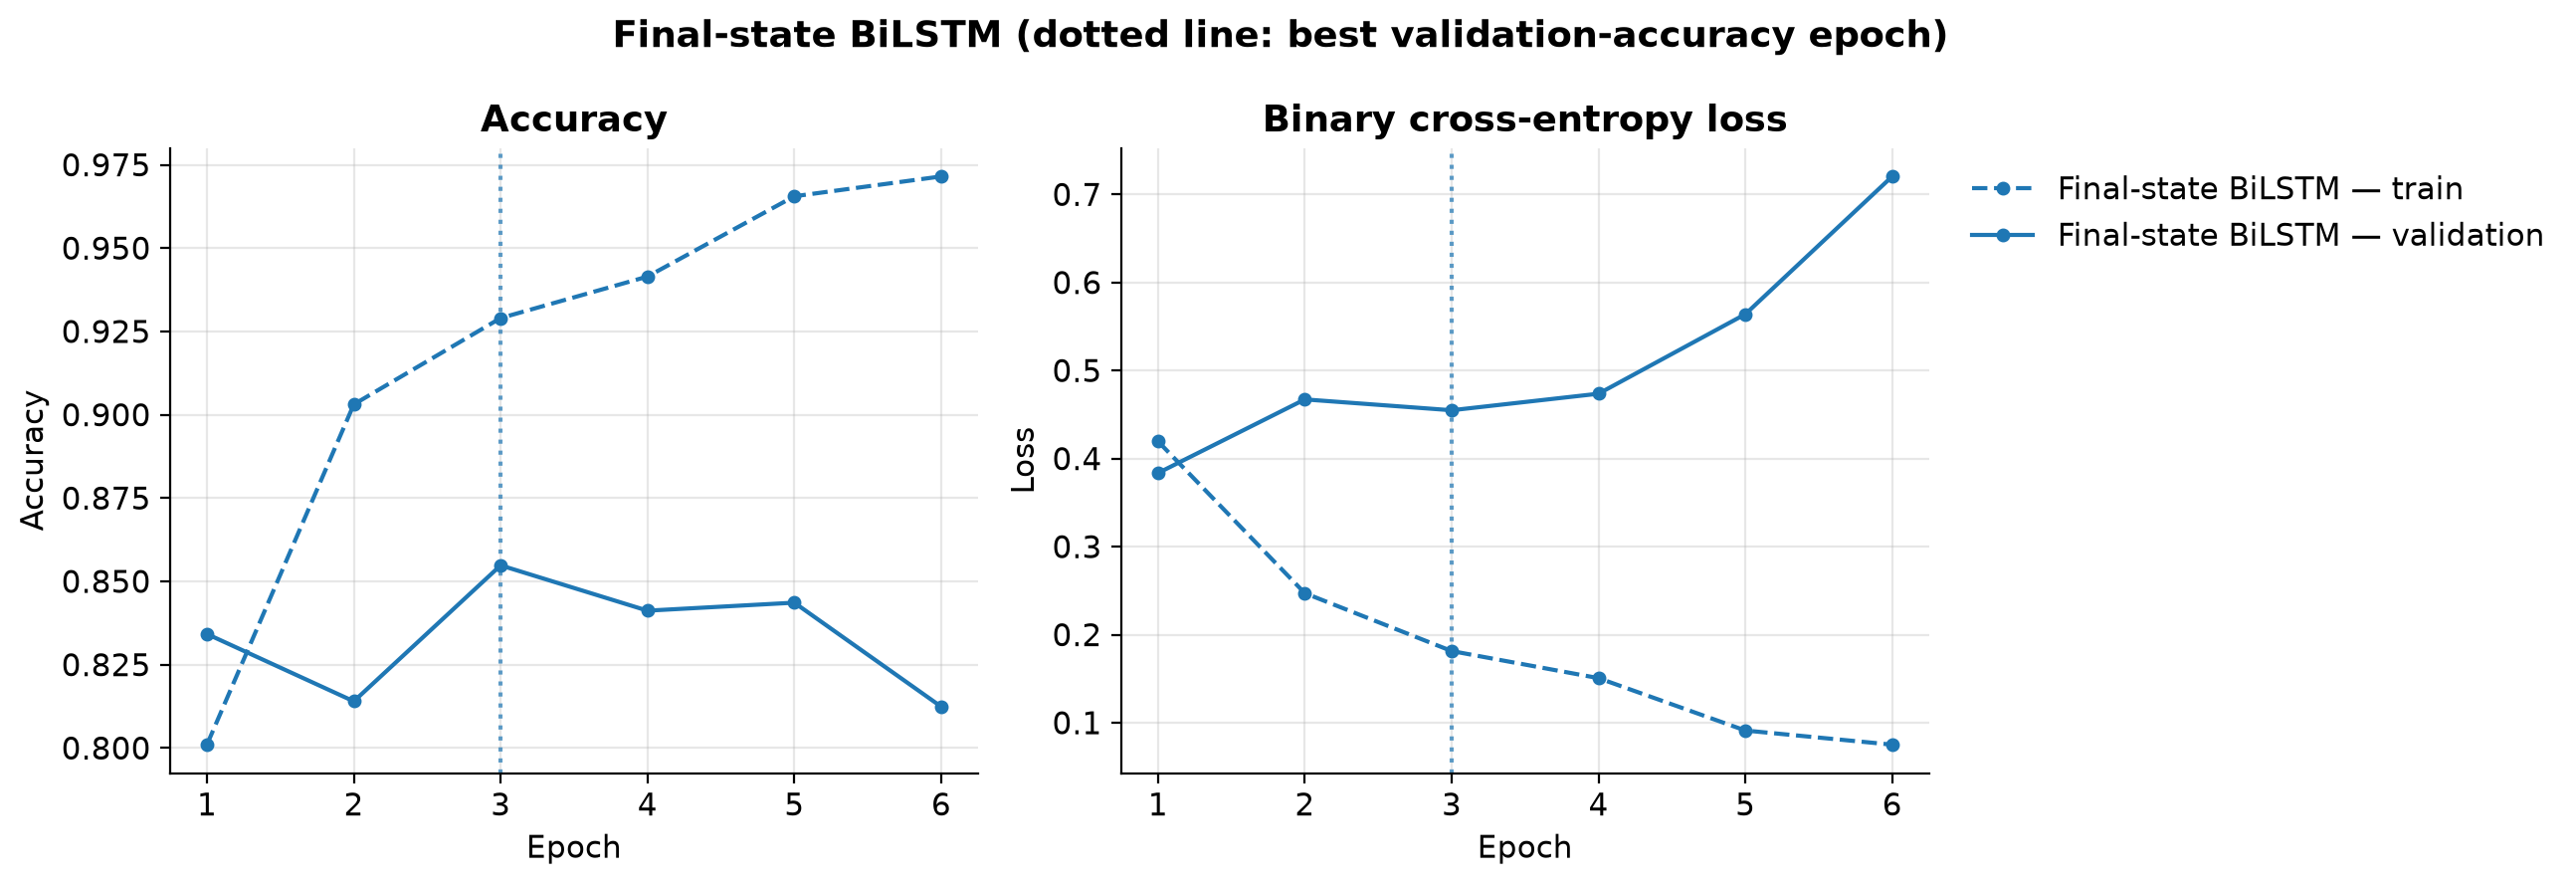

,accuracy,loss,val_accuracy,val_loss,seconds
epoch,,,,,
1,0.8010,0.4196,0.8342,0.3835,18.2398
2,0.9031,0.2471,0.8140,0.4672,4.1809
3,0.9290,0.1814,0.8548,0.4549,4.1757
4,0.9414,0.1506,0.8412,0.4736,4.1596
5,0.9656,0.0912,0.8436,0.5639,4.1862
6,0.9715,0.0751,0.8124,0.7204,4.1711


,Final-state BiLSTM
Epochs run,6
Best epoch,3
Best val accuracy,0.8548
Train accuracy (best epoch),0.9290
Accuracy gap (train − val),0.0742
Val loss (best epoch),0.4549
Lowest val loss,0.3835
Epoch of lowest val loss,1
Total parameters,"1,387,137"
Trainable parameters,"1,387,137"


In [14]:
plot_history([baseline_run], "Final-state BiLSTM")
display(baseline_run.history.round(4))
summary_frame([baseline_run])

### Baseline interpretation

**Convergence and stability.** The baseline learns quickly: validation accuracy is 0.8342 after one epoch and peaks at **0.8548 at epoch 3**. The path is not smooth. Validation accuracy drops 2.0 points at epoch 2 (0.8140), jumps 4.1 points at epoch 3, then moves between 0.8124 and 0.8436. Early stopping (patience 3) ends the run after epoch 6 and restores the epoch-3 weights.

**Underfitting or overfitting.** The model overfits early; it does not underfit. Training accuracy climbs steadily from 0.8010 to 0.9715 and training loss falls from 0.42 to 0.075. Validation loss is lowest after epoch 1 (0.3835) and rises almost every epoch after, to 0.7204 at epoch 6, so the network starts to memorise the training reviews after its first pass over the data. At the best epoch the train − validation accuracy gap is 7.4 points (0.9290 vs 0.8548). Validation accuracy peaks two epochs after validation loss bottoms out: the model keeps most reviews on the right side of 0.5 while its probabilities become overconfident, which cross-entropy penalises.

**Best validation accuracy:** 0.8548 at epoch 3 of 6.

**Limitations of the final-state summary.** The classifier sees only two vectors per review: the forward state after the last kept token and the backward state after the first. Everything the model uses must survive the LSTM's gated, step-by-step compression into those two fixed-size states, so a decisive sentence in the middle of a 200-token review must be carried across up to a hundred updates by both directions to reach the classifier. LSTM gates reduce, but do not remove, this recency bias: the forward state is dominated by the end of the kept text and the backward state by its beginning. Because truncation keeps the first 200 tokens, the forward state's "end" is often an arbitrary cut point mid-review rather than the reviewer's conclusion. Finally, the summary exposes nothing about which tokens mattered; there is no per-token signal to inspect.

The test set is not used here.

## Step 3 — Custom additive attention-pooling layer

The layer receives the full BiLSTM output $H = (h_1, \dots, h_T)$, shape `(batch_size, T, hidden_dim)` with `hidden_dim = 128`, plus the padding mask $m_t \in \{0, 1\}$ that Keras propagates from the embedding.

$$e_t = v^\top \tanh\!\left(W^\top h_t + b\right) \qquad \text{(alignment score, one scalar per time step)}$$

$$\alpha_t = \frac{m_t \exp(e_t)}{\sum_{j=1}^{T} m_j \exp(e_j)} \qquad \text{(softmax over valid positions only)}$$

$$c = \sum_{t=1}^{T} \alpha_t h_t \qquad \text{(context vector, one per review)}$$

The brief writes the score as $v^\top \tanh(W h_t + b)$, with $W$ mapping `hidden_dim` to `attention_dim`. Here, as in the starter code, $W$ is stored as `(hidden_dim, attention_dim)`, so the same product appears as $W^\top h_t$ and is computed as `hidden_states @ W`. The mask is applied by replacing the scores at padded positions with $-10^9$ before the softmax; $\exp(-10^9)$ underflows to exactly 0, which is the same as multiplying by $m_t$. The layer subclasses `keras.layers.Layer`, which in TensorFlow 2.16 and later is the same class as `tf.keras.layers.Layer`, and uses no built-in attention layer. It builds on the starter structure in the assignment brief; `call`, `compute_mask`, and `get_config` are completed below.

In [15]:
class AdditiveAttentionPooling(layers.Layer):
    """Bahdanau-style additive attention pooling over a masked sequence (no decoder query).

    Input:  hidden_states (batch, T, hidden_dim), optional boolean mask (batch, T).
    Output: context (batch, hidden_dim) and attention weights (batch, T).
    """

    MASK_VALUE = -1e9  # score for padded positions; exp() of it underflows to 0

    def __init__(self, attention_dim, **kwargs):
        super().__init__(**kwargs)
        self.attention_dim = attention_dim
        self.supports_masking = True

    def build(self, input_shape):
        hidden_dim = input_shape[-1]

        self.W = self.add_weight(
            name="attention_weight",
            shape=(hidden_dim, self.attention_dim),
            initializer="glorot_uniform",
            trainable=True,
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(self.attention_dim,),
            initializer="zeros",
            trainable=True,
        )

        self.v = self.add_weight(
            name="attention_vector",
            shape=(self.attention_dim, 1),
            initializer="glorot_uniform",
            trainable=True,
        )

    def call(self, hidden_states, mask=None):
        # 1. Additive alignment scores: e_t = v^T tanh(W^T h_t + b)  → (batch, T)
        projected = tf.tanh(tf.tensordot(hidden_states, self.W, axes=1) + self.b)
        scores = tf.squeeze(tf.tensordot(projected, self.v, axes=1), axis=-1)

        # 2. Padding mask: padded positions get a score whose exp() is 0
        if mask is not None:
            scores = tf.where(mask, scores, tf.cast(self.MASK_VALUE, scores.dtype))

        # 3. Softmax over the time axis → weights sum to 1 over valid positions
        weights = tf.nn.softmax(scores, axis=-1)

        # 4. Context vector: attention-weighted sum of hidden states → (batch, hidden_dim)
        context = tf.reduce_sum(hidden_states * weights[..., tf.newaxis], axis=1)

        # 5. Both outputs
        return context, weights

    def compute_mask(self, inputs, mask=None):
        # The time axis is pooled away, so neither output carries a mask downstream.
        return [None, None]

    def get_config(self):
        return {**super().get_config(), "attention_dim": self.attention_dim}

### Unit checks on the layer

Before the layer goes into a model, a small synthetic batch confirms its contract: output shapes, weights that sum to 1, exactly zero weight on padded positions, a context equal to the explicit weighted sum, and invariance to padding (a sequence of 3 real steps padded to 6 gives the same context as the 3 steps alone).

In [16]:
def check_attention_layer() -> pd.DataFrame:
    """Contract checks for AdditiveAttentionPooling on a synthetic masked batch."""
    probe = AdditiveAttentionPooling(attention_dim=16)
    hidden = tf.random.normal((2, 6, 8), seed=SEED)
    mask = tf.sequence_mask([3, 6], maxlen=6)  # row 0: 3 real steps + 3 padded
    context, weights = probe(hidden, mask=mask)
    unpadded_context, _ = probe(hidden[:1, :3])  # row 0 without its padding, no mask
    explicit = tf.einsum("bt,bth->bh", weights, hidden)
    checks = {
        "context shape == (2, 8)": tuple(context.shape) == (2, 8),
        "weights shape == (2, 6)": tuple(weights.shape) == (2, 6),
        "weights sum to 1 per row": bool(np.allclose(tf.reduce_sum(weights, axis=1), 1.0)),
        "padded positions get weight 0": bool(np.all(weights.numpy()[0, 3:] == 0)),
        "context == Σ α_t h_t": bool(np.allclose(context, explicit, atol=1e-6)),
        "padding does not change the context": bool(np.allclose(context[:1], unpadded_context, atol=1e-6)),
    }
    return pd.DataFrame({"Passed": checks})


check_attention_layer()

,Passed
"context shape == (2, 8)",True
"weights shape == (2, 6)",True
weights sum to 1 per row,True
padded positions get weight 0,True
context == Σ α_t h_t,True
padding does not change the context,True


### Roles of the components

- **$W$ (`hidden_dim × attention_dim`, here 128 × 64)** projects each 128-dimensional hidden state into a 64-dimensional "attention space". Its columns are learned feature detectors: directions in hidden-state space that are useful for deciding whether a position is relevant to the sentiment decision. The same $W$ is applied at every time step, so the scoring function is position-independent and works for any review length.
- **$b$ (`attention_dim`)** is a learned offset added inside the $\tanh$. It shifts each projected feature relative to $\tanh$'s linear region, setting how strongly a feature must be present before it pushes the score up or down.
- **$\tanh$** makes the scoring function nonlinear and bounded, which is what makes it *additive* (Bahdanau-style) rather than a plain dot product: the score is a small learned MLP of the hidden state.
- **$v$ (`attention_dim × 1`)** collapses the 64 projected features into one scalar score $e_t$ per position. It plays the role of a learned, fixed query: positions whose projected features align with $v$ score high. Unlike seq2seq Bahdanau attention there is no decoder state; $v$ is the same for every review.
- **Softmax** turns the unbounded scores into a probability distribution over the valid positions: every weight is non-negative, the weights sum to 1, and differences in score become multiplicative differences in weight, so a few high-scoring positions can dominate. The mask applied first ensures the distribution covers real tokens only.
- **The context vector $c$** is the attention-weighted average of all hidden states. It replaces the baseline's final-state summary: a fixed-size (128-dimensional) representation of the whole review in which positions the model scored as relevant contribute most, wherever they occur. The dense head classifies from $c$, and the weights $\alpha_t$ are returned alongside it so the selection can be inspected in Step 5.

The layer adds $128 \times 64 + 64 + 64 = 8{,}320$ trainable parameters.

## Step 4 — Attention-based BiLSTM

### Controlled comparison

| | Final-state BiLSTM | Attention-based BiLSTM |
|---|---|---|
| Training / validation data | 20,000 / 5,000 reviews, same split | same |
| Preprocessing | 200 tokens, post-pad, post-truncate | same |
| Embedding | 10,000 × 128, `mask_zero=True` | same |
| BiLSTM | 64 units per direction | same, with `return_sequences=True` |
| **Sequence summary** | **$[\overrightarrow{h}_{T} ; \overleftarrow{h}_{1}]$** | **$c = \sum_t \alpha_t h_t$ (custom layer)** |
| Head | Dense(64, ReLU) → Dense(1, sigmoid) | same |
| Optimizer, learning rate | Adam, $10^{-3}$ | same |
| Loss, metric | Binary cross-entropy, accuracy | same |
| Batch size, max epochs | 64, 10 | same |
| Early stopping | val accuracy, patience 3, restore best | same |
| Seed | 42, reset before building | same |

The summary step is the only independent variable, so a difference in validation behavior can be attributed to it, within the run-to-run variation that a single seed cannot measure. The model used for training outputs only the probability; a second `keras.Model`, `attention_explainer`, shares every layer with it and also outputs the attention weights for Step 5.

In [17]:
def build_attention() -> tuple[keras.Model, keras.Model]:
    """Embedding → BiLSTM (all states) → additive attention pooling → dense head → sigmoid.

    Returns the trainable classifier and an explainer that shares its layers and
    additionally outputs the attention weights.
    """
    keras.utils.set_random_seed(SEED)
    tokens = keras.Input(shape=(MAX_LEN,), dtype="int32", name="tokens")
    hidden_states = encode(tokens, return_sequences=True)  # (batch, T, 2 × LSTM_UNITS)
    context, attention = AdditiveAttentionPooling(ATTENTION_DIM, name="attention")(hidden_states)
    outputs = classification_head(context)
    classifier = compile_model(keras.Model(tokens, outputs, name="attention_bilstm"))
    explainer = keras.Model(tokens, [outputs, attention], name="attention_explainer")
    return classifier, explainer


attention_model, attention_explainer = build_attention()
attention_model.summary()

same_start = all(
    np.array_equal(a, b)
    for a, b in zip(baseline_initial_encoder, encoder_weights(attention_model))
)
print(f"Embedding and BiLSTM start from the same weights as the baseline: {same_start}")

Model: "attention_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, 200)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 128)  │  1,280,000 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 200)       │          0 │ tokens[0][0]      │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 200, 128)  │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 128),     │      8,320 │ bilstm[0][0],     │
│ (AdditiveAttention… │ (None, 200)]      │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dense (Dense)  │ (None, 64)        │      8,256 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ head_dense[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,395,457 (5.32 MB)

 Trainable params: 1,395,457 (5.32 MB)

 Non-trainable params: 0 (0.00 B)

Embedding and BiLSTM start from the same weights as the baseline: True


In [18]:
attention_run = train("Attention-based BiLSTM", attention_model)

Epoch 1/10


313/313 - 7s - 22ms/step - accuracy: 0.8137 - loss: 0.3979 - val_accuracy: 0.8340 - val_loss: 0.3733


Epoch 2/10


313/313 - 4s - 14ms/step - accuracy: 0.9125 - loss: 0.2248 - val_accuracy: 0.8350 - val_loss: 0.4077


Epoch 3/10


313/313 - 4s - 14ms/step - accuracy: 0.9459 - loss: 0.1509 - val_accuracy: 0.8422 - val_loss: 0.4984


... (4 outputs left out)

Epoch 6/10


313/313 - 4s - 14ms/step - accuracy: 0.9697 - loss: 0.0798 - val_accuracy: 0.8240 - val_loss: 0.7149


Epoch 7/10


313/313 - 4s - 14ms/step - accuracy: 0.9735 - loss: 0.0726 - val_accuracy: 0.7956 - val_loss: 0.6725


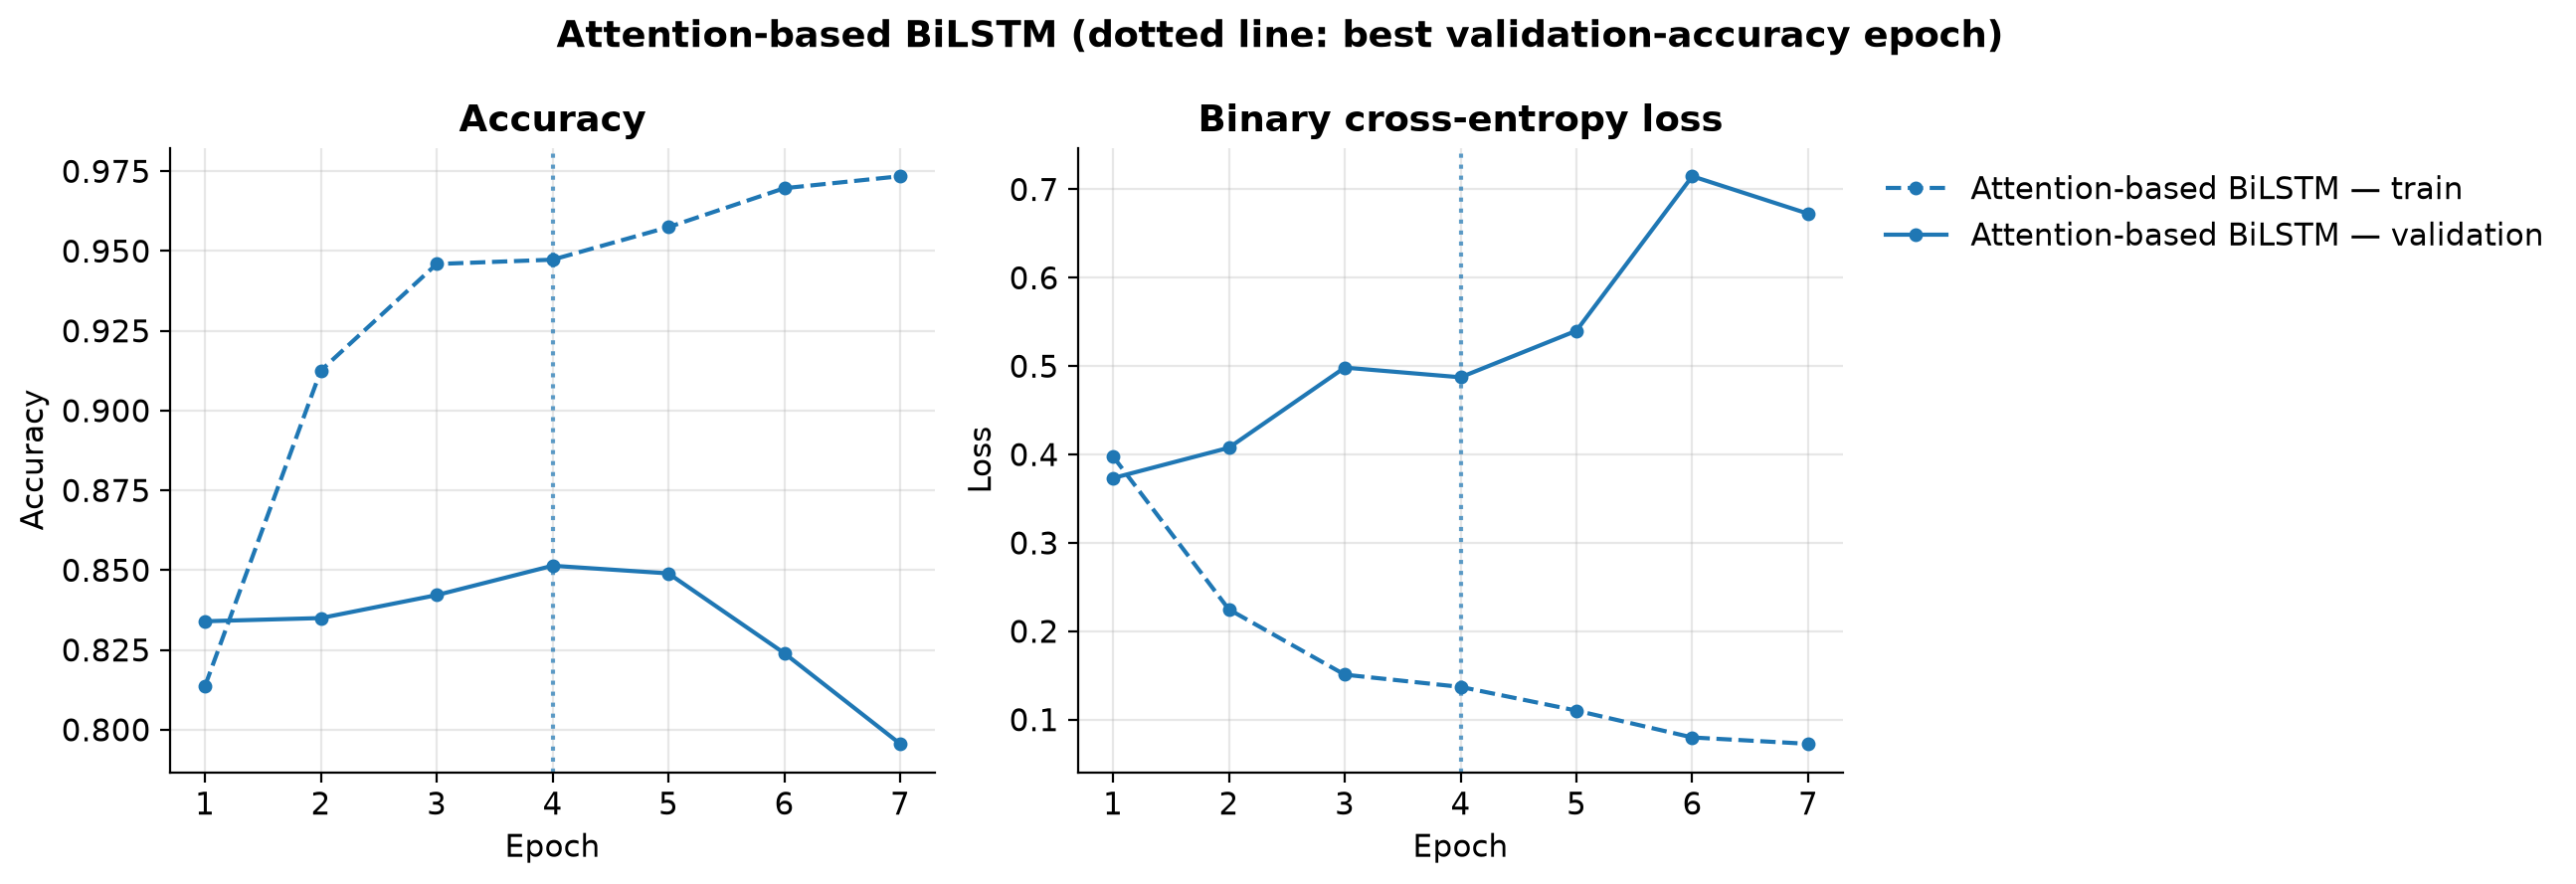

,accuracy,loss,val_accuracy,val_loss,seconds
epoch,,,,,
1,0.8137,0.3979,0.8340,0.3733,6.7342
2,0.9125,0.2248,0.8350,0.4077,4.4352
3,0.9459,0.1509,0.8422,0.4984,4.4461
4,0.9473,0.1370,0.8514,0.4874,4.4523
5,0.9575,0.1102,0.8490,0.5401,4.4448
6,0.9697,0.0798,0.8240,0.7149,4.4491
7,0.9735,0.0726,0.7956,0.6725,4.4686


In [19]:
plot_history([attention_run], "Attention-based BiLSTM")
display(attention_run.history.round(4))

### Side-by-side comparison

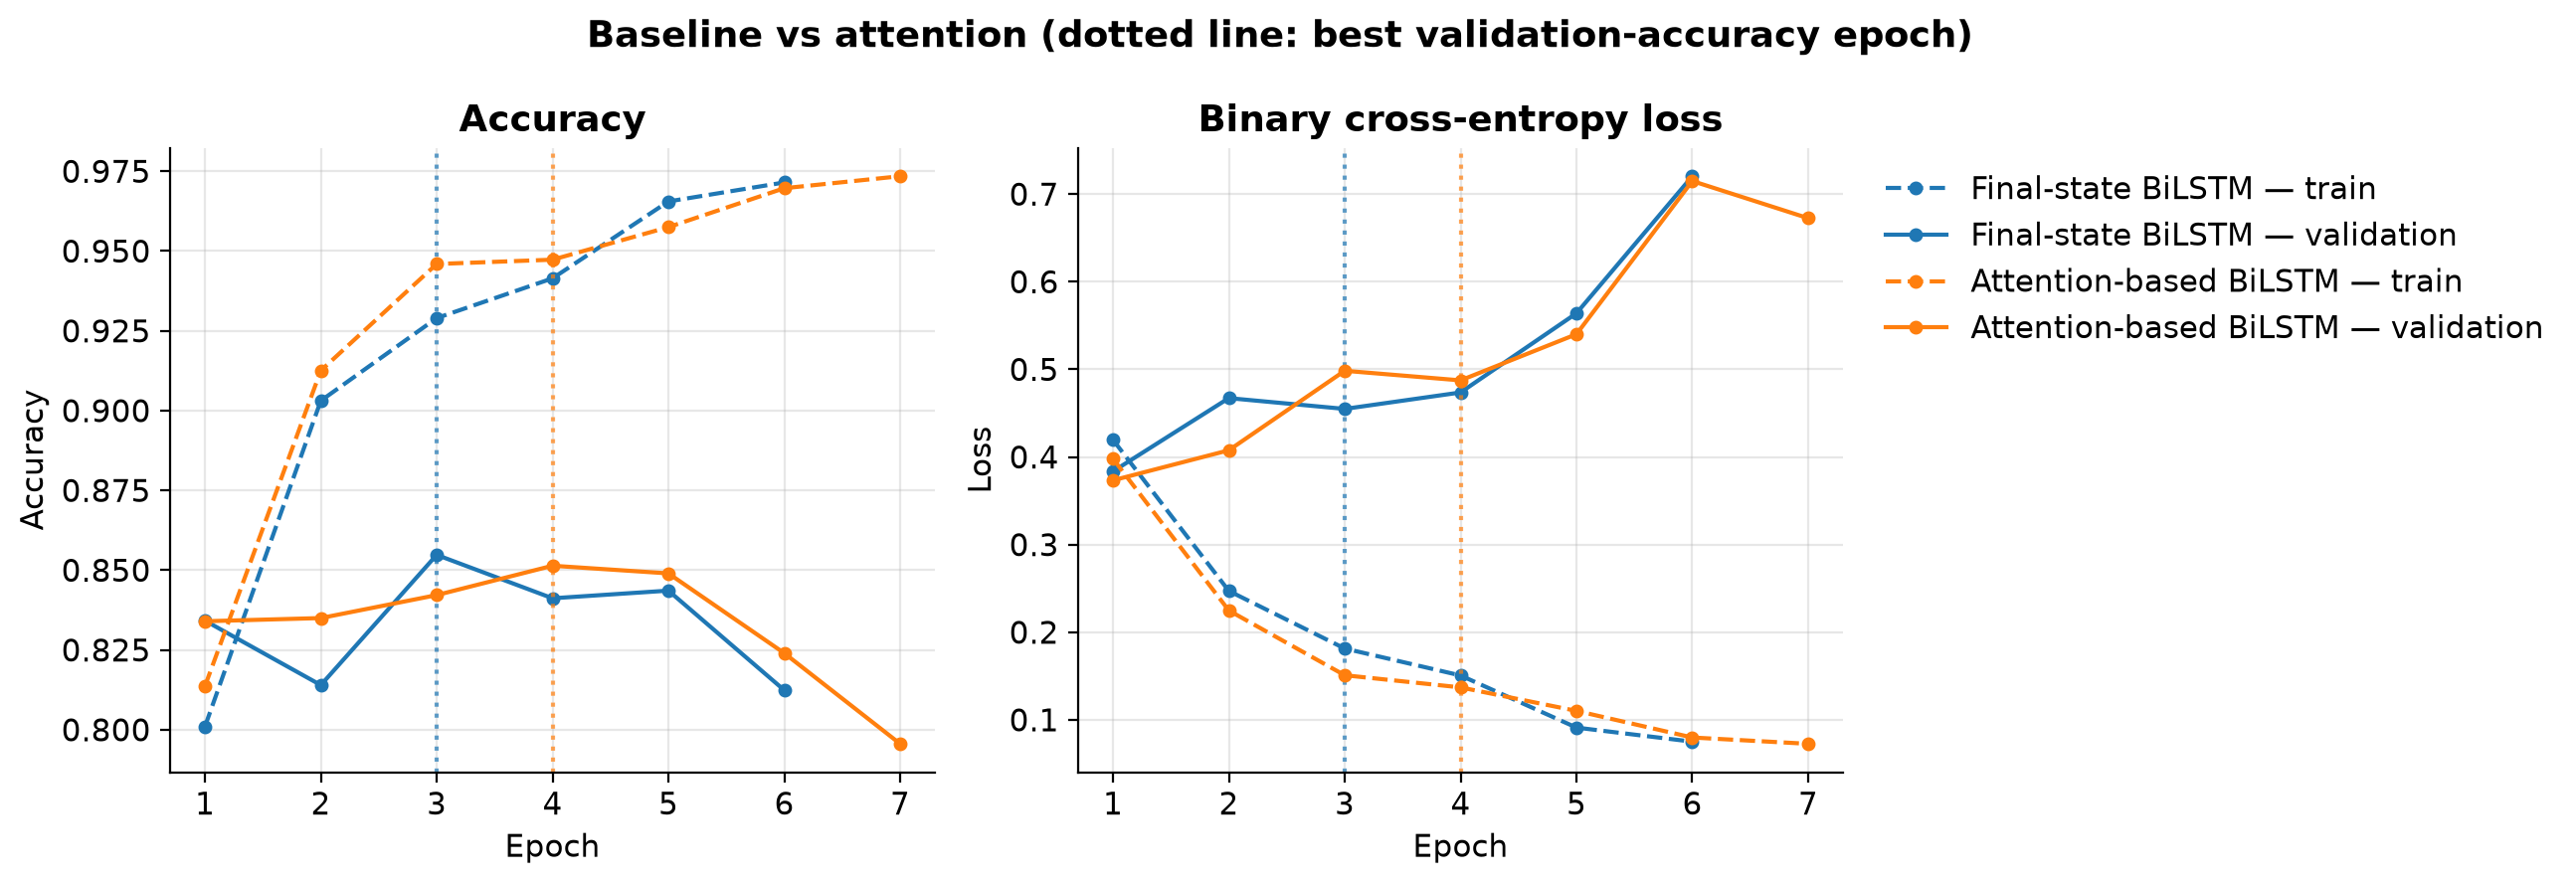

,Final-state BiLSTM,Attention-based BiLSTM
Epochs run,6,7
Best epoch,3,4
Best val accuracy,0.8548,0.8514
Train accuracy (best epoch),0.9290,0.9473
Accuracy gap (train − val),0.0742,0.0959
Val loss (best epoch),0.4549,0.4874
Lowest val loss,0.3835,0.3733
Epoch of lowest val loss,1,1
Total parameters,"1,387,137","1,395,457"
Trainable parameters,"1,387,137","1,395,457"


In [20]:
runs = {run.name: run for run in (baseline_run, attention_run)}
plot_history(list(runs.values()), "Baseline vs attention")
comparison = summary_frame(list(runs.values()))
comparison

### Comparison with the baseline

All numbers come from the table and the overlaid curves above. Both runs used the same data, initial encoder weights and training settings, so the summary step is the only difference.

**Convergence.** After one epoch the two models are level (0.8340 vs 0.8342 validation accuracy), but attention reaches a lower validation loss (0.3733 vs 0.3835). The baseline peaks sooner (epoch 3) and the attention model one epoch later (epoch 4).

**Stability.** The attention model's validation accuracy rises every epoch up to its peak (0.8340 → 0.8350 → 0.8422 → 0.8514), while the baseline dips at epoch 2 before peaking. After the peak, attention degrades faster: it is 5.6 points down by epoch 7 (0.7956), while the baseline's worst post-peak epoch is 4.2 points down (0.8124).

**Best validation accuracy.** Baseline 0.8548, attention 0.8514: the baseline is ahead by **0.34 points, or 17 of 5,000 reviews**. That is smaller than the sampling error of either estimate (about 0.5 points at 85% accuracy on 5,000 reviews), and each model was trained once. Run-to-run variation is at least as large. `enable_op_determinism` makes runs repeatable only on identical hardware and software: two executions of this notebook on GPU nodes with drivers 545 and 570 produced exactly these outputs, but an execution on a node with driver 595 gave 0.8380 for the baseline and 0.8522 for attention, reversing the order (those outputs are not shown here). The evidence therefore does not show that either summary step is more accurate.

**Generalization gap.** At the best epoch the gap is 9.6 points for attention (0.9473 vs 0.8514) and 7.4 for the baseline. Both models overfit from epoch 2 in loss terms: validation loss is lowest after epoch 1 for both and has nearly doubled by epoch 6 (0.7149 and 0.7204). Attention fits the training set slightly faster, which is consistent with the head having direct access to every hidden state.

**Parameters.** 1,395,457 vs 1,387,137, all trainable. The attention layer adds exactly 8,320 ($W$: 128 × 64 = 8,192; $b$: 64; $v$: 64), 0.6% of the baseline. The embedding alone holds 1,280,000 of the baseline's parameters (92%).

**Training time** (NVIDIA L40S, from the setup cell). After the first epoch, attention costs 4.4 s per epoch against 4.2 s, about 0.3 s (7%) more in the unrounded epoch times: the price of scoring all 200 positions. The totals favour attention (33.5 s for 7 epochs vs 39.3 s for 6) only because the baseline's first epoch (18.2 s) also absorbed one-off GPU and graph set-up. On this hardware the cost difference is negligible.

## Step 5 — Analyze attention weights

The explainer returns, for every validation review, the predicted probability and the 200 attention weights. Padded positions carry weight 0 by construction, so trimming each review to its real length loses no attention mass.

Five reviews are selected by a fixed rule:

| Case | Rule |
|---|---|
| Correct positive | Correctly classified, label 1, not truncated; highest predicted probability |
| Correct negative | Correctly classified, label 0, not truncated; lowest predicted probability |
| Incorrect | Misclassified; the most confident error |
| Low confidence | Predicted probability closest to 0.5 |
| Truncated | Correctly classified, longer than 200 tokens; the most confident, to show what truncation hides |

Choosing untruncated reviews for the first two keeps their attention map complete; the truncated case is added on purpose for the truncation discussion.

In [21]:
val_probs, val_attention = attention_explainer.predict(X_val, batch_size=256, verbose=0)
val_probs = val_probs.ravel()
val_pred = (val_probs >= THRESHOLD).astype(int)
val_lengths = (X_val != 0).sum(axis=1)  # real tokens kept per review
val_truncated = val_raw_lengths > MAX_LEN

padded_mass = np.where(X_val == 0, val_attention, 0).max()
print(f"Largest attention weight on any padded position: {padded_mass:.2e}")
print(f"Validation accuracy recomputed from the explainer: {np.mean(val_pred == y_val):.4f}")


def pick_cases() -> dict[str, int]:
    """Validation indices for the five analysis cases (rules in the table above)."""
    correct = val_pred == y_val
    confidence = np.abs(val_probs - 0.5)
    everyone = np.ones(len(y_val), dtype=bool)

    def extreme(pool: np.ndarray, key: np.ndarray) -> int:
        candidates = np.flatnonzero(pool)
        return int(candidates[np.argmax(key[candidates])])

    return {
        "Correct positive": extreme(correct & (y_val == 1) & ~val_truncated, val_probs),
        "Correct negative": extreme(correct & (y_val == 0) & ~val_truncated, -val_probs),
        "Incorrect": extreme(~correct, confidence),
        "Low confidence": extreme(everyone, -confidence),
        "Truncated": extreme(correct & val_truncated, confidence),
    }


cases = pick_cases()
pd.DataFrame(
    {
        "Validation index": cases.values(),
        "True label": [LABELS[int(y_val[i])] for i in cases.values()],
        "P(positive)": [val_probs[i] for i in cases.values()],
        "Predicted": [LABELS[int(val_pred[i])] for i in cases.values()],
        "Tokens (original)": [val_raw_lengths[i] for i in cases.values()],
        "Tokens kept": [val_lengths[i] for i in cases.values()],
    },
    index=pd.Index(cases.keys(), name="Case"),
).round(4)

Largest attention weight on any padded position: 0.00e+00
Validation accuracy recomputed from the explainer: 0.8514


,Validation index,True label,P(positive),Predicted,Tokens (original),Tokens kept
Case,,,,,,
Correct positive,348,positive,1.0000,positive,57,57
Correct negative,3950,negative,0.0000,negative,52,52
Incorrect,2042,negative,1.0000,positive,193,193
Low confidence,3479,positive,0.5013,positive,158,158
Truncated,1256,positive,1.0000,positive,346,200


In [22]:
def token_attention(i: int) -> pd.DataFrame:
    """Real tokens of validation review i aligned with their attention weights."""
    n = val_lengths[i]
    weights = val_attention[i, :n]
    return pd.DataFrame(
        {
            "position": np.arange(n),
            "token": decode(X_val[i, :n]),
            "weight": weights,
            "× uniform": weights * n,  # 1.0 = the weight every token would get under uniform attention
        }
    )


def highlight_html(tokens: pd.DataFrame) -> str:
    """Review text with each word's background opacity proportional to its weight."""
    peak = tokens["weight"].max()
    spans = [
        f'<span title="{w:.4f}" style="background: rgba(214, 39, 40, {w / peak:.3f}); '
        f'padding: 1px 2px; border-radius: 3px">{escape(t)}</span>'
        for t, w in zip(tokens["token"], tokens["weight"])
    ]
    return f'<div style="line-height: 1.9; font-family: monospace; font-size: 12px">{" ".join(spans)}</div>'


def plot_case(case: str, i: int, tokens: pd.DataFrame, top_k: int = 12) -> None:
    """Attention over positions (left) and the top-k weighted tokens (right)."""
    top = tokens.nlargest(top_k, "weight")
    fig, (ax_pos, ax_top) = plt.subplots(
        1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]}
    )
    ax_pos.bar(tokens["position"], tokens["weight"], width=1.0, color="C0")
    ax_pos.axhline(1 / len(tokens), color="k", ls=":", label=f"Uniform (1/{len(tokens)})")
    for _, row in top.head(5).iterrows():
        ax_pos.annotate(
            row["token"], (row["position"], row["weight"]), ha="center", va="bottom", fontsize=9
        )
    ax_pos.set(title="Attention across the review", xlabel="Token position", ylabel="Attention weight")
    ax_pos.legend()
    labels = top["token"] + "  @" + top["position"].astype(str)
    ax_top.barh(labels[::-1], top["weight"][::-1], color="C3")
    ax_top.set(title=f"Top {top_k} tokens (word @ position)", xlabel="Attention weight")
    fig.suptitle(
        f"{case}: true {LABELS[int(y_val[i])]}, P(positive) = {val_probs[i]:.3f}, "
        f"{len(tokens)} tokens kept of {val_raw_lengths[i]}",
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


def show_case(case: str, i: int) -> None:
    """Top weighted words, both plots, and the highlighted text for one case."""
    tokens = token_attention(i)
    display(HTML(f"<h4>{escape(case)} — validation review #{i}</h4>"))
    display(tokens.nlargest(10, "weight").round(4).set_index("position"))
    plot_case(case, i, tokens)
    display(HTML(highlight_html(tokens)))

,token,weight,× uniform
position,,,
34,wonderfully,0.1552,8.8488
29,vance,0.1263,7.1990
35,relaxed,0.1000,5.6998
1,cracking,0.0614,3.5026
48,recommend,0.0541,3.0827
30,series,0.0418,2.3811
36,and,0.0322,1.8337
28,philo,0.0289,1.6447
32,powell,0.0286,1.6318


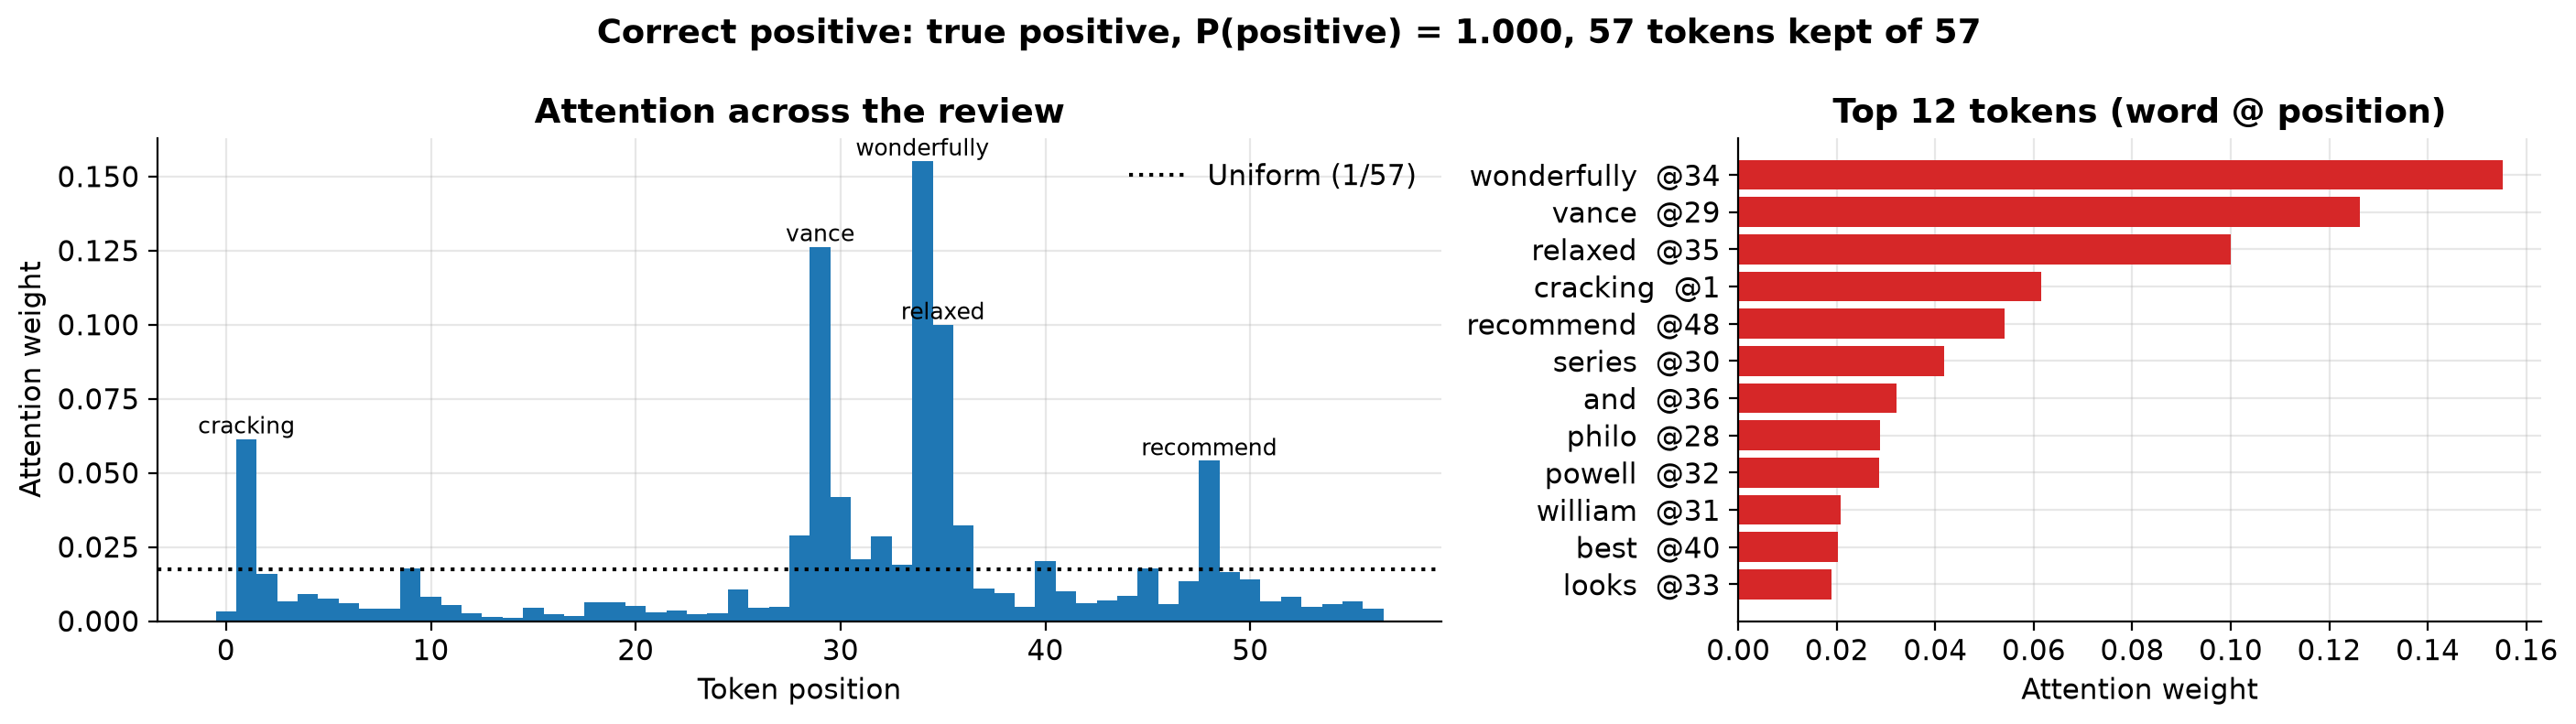

In [23]:
show_case("Correct positive", cases["Correct positive"])

,token,weight,× uniform
position,,,
3,feeble,0.1741,9.0510
47,dire,0.1365,7.0975
49,lifeless,0.1251,6.5075
4,characterization,0.0865,4.4966
50,script,0.0627,3.2598
2,dialogue,0.0538,2.7992
1,turgid,0.0489,2.5419
51,avoid,0.0414,2.1547
0,<start>,0.0372,1.9348


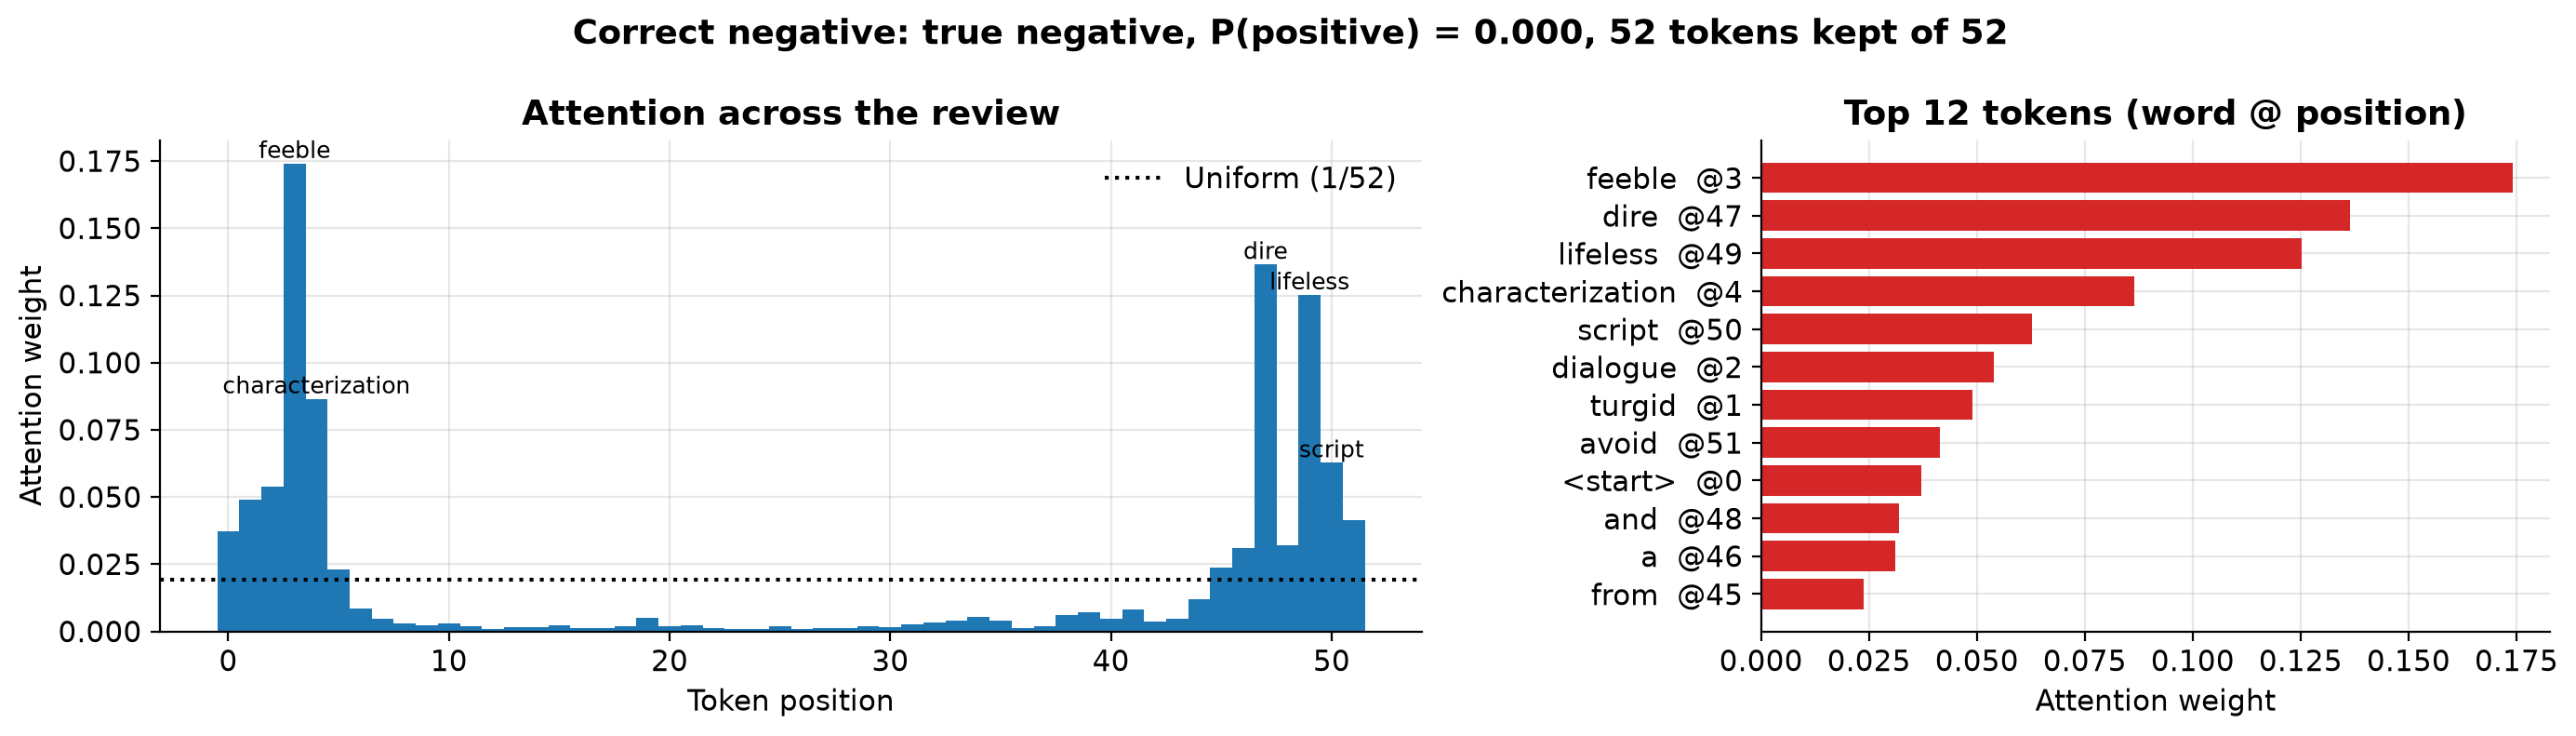

In [24]:
show_case("Correct negative", cases["Correct negative"])

,token,weight,× uniform
position,,,
9,mildred,0.2360,45.5435
7,job,0.0312,6.0167
10,i,0.0295,5.6925
60,howard,0.0264,5.1013
45,job,0.0256,4.9476
164,recommend,0.0253,4.8753
11,felt,0.0232,4.4786
165,this,0.0225,4.3415
6,wonderful,0.0212,4.0826


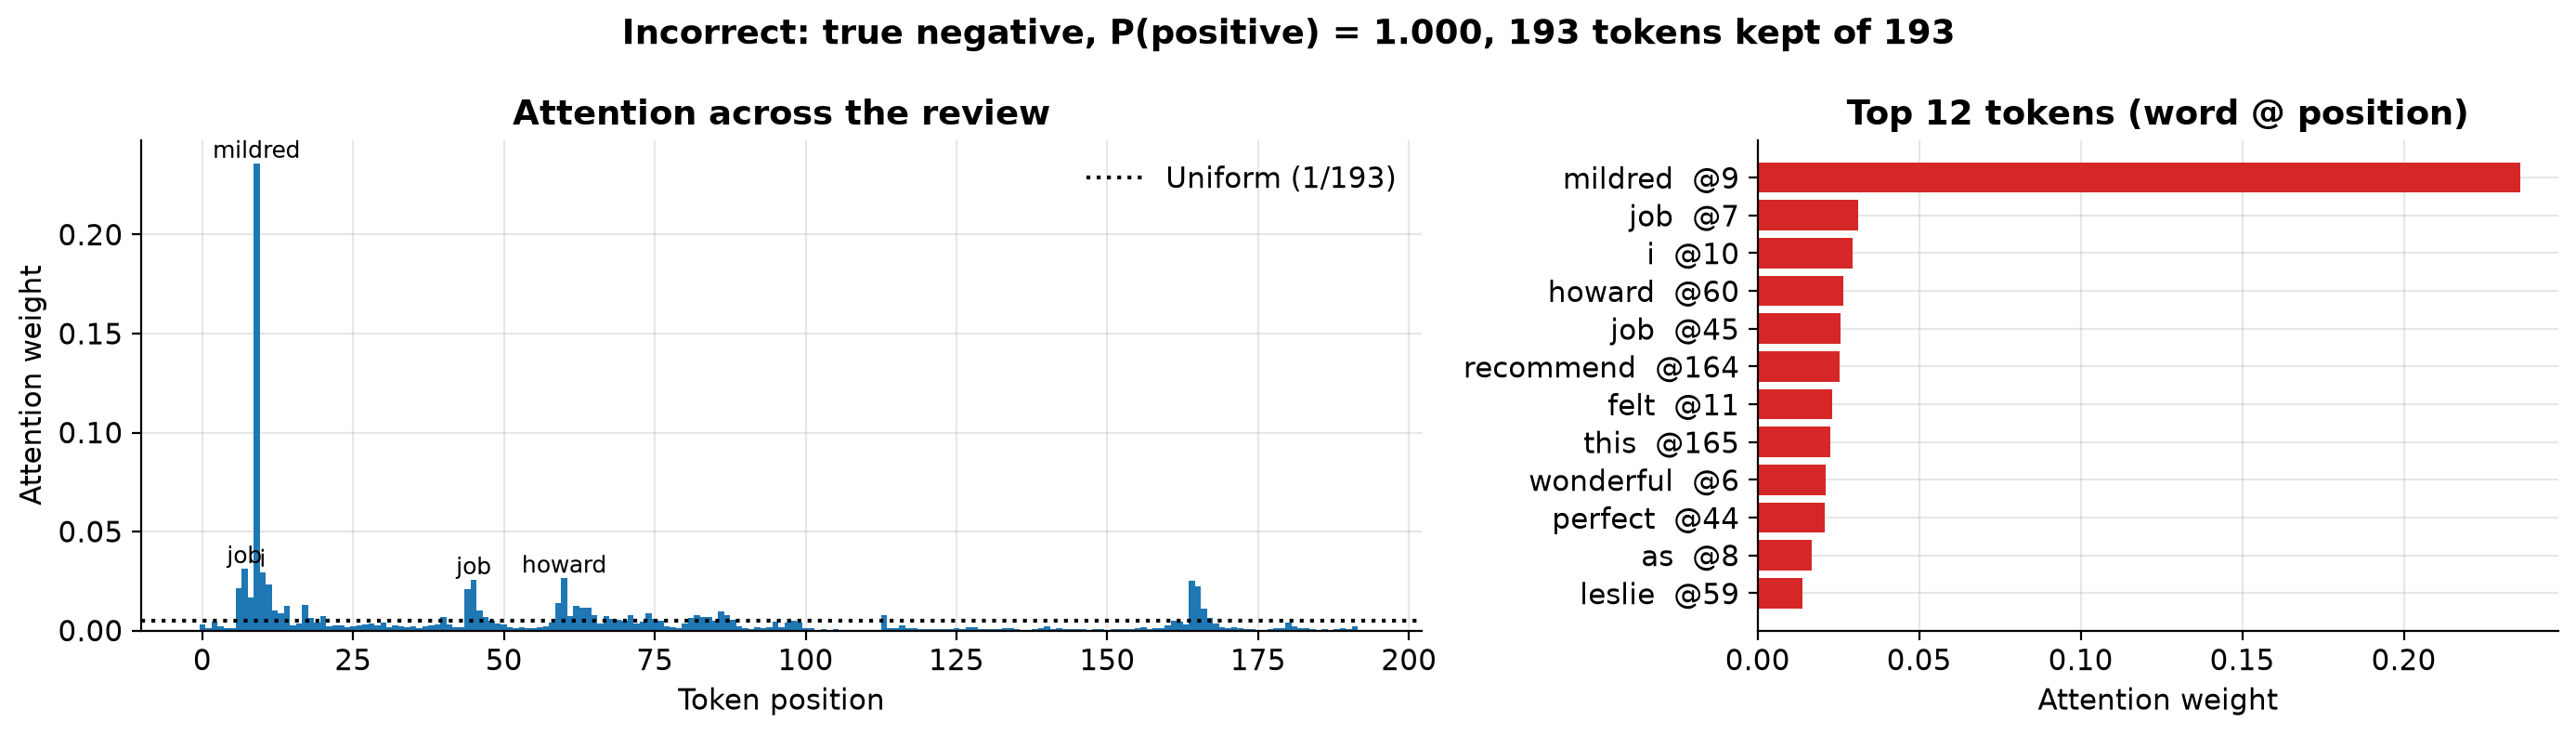

In [25]:
show_case("Incorrect", cases["Incorrect"])

,token,weight,× uniform
position,,,
17,laura,0.0788,12.4467
16,carmen,0.0672,10.6111
13,brings,0.0459,7.2480
15,sexy,0.0421,6.6594
11,antonio,0.0353,5.5788
9,choreographer,0.0341,5.3938
14,the,0.0323,5.1073
10,antonio,0.0313,4.9375
109,absolutely,0.0263,4.1495


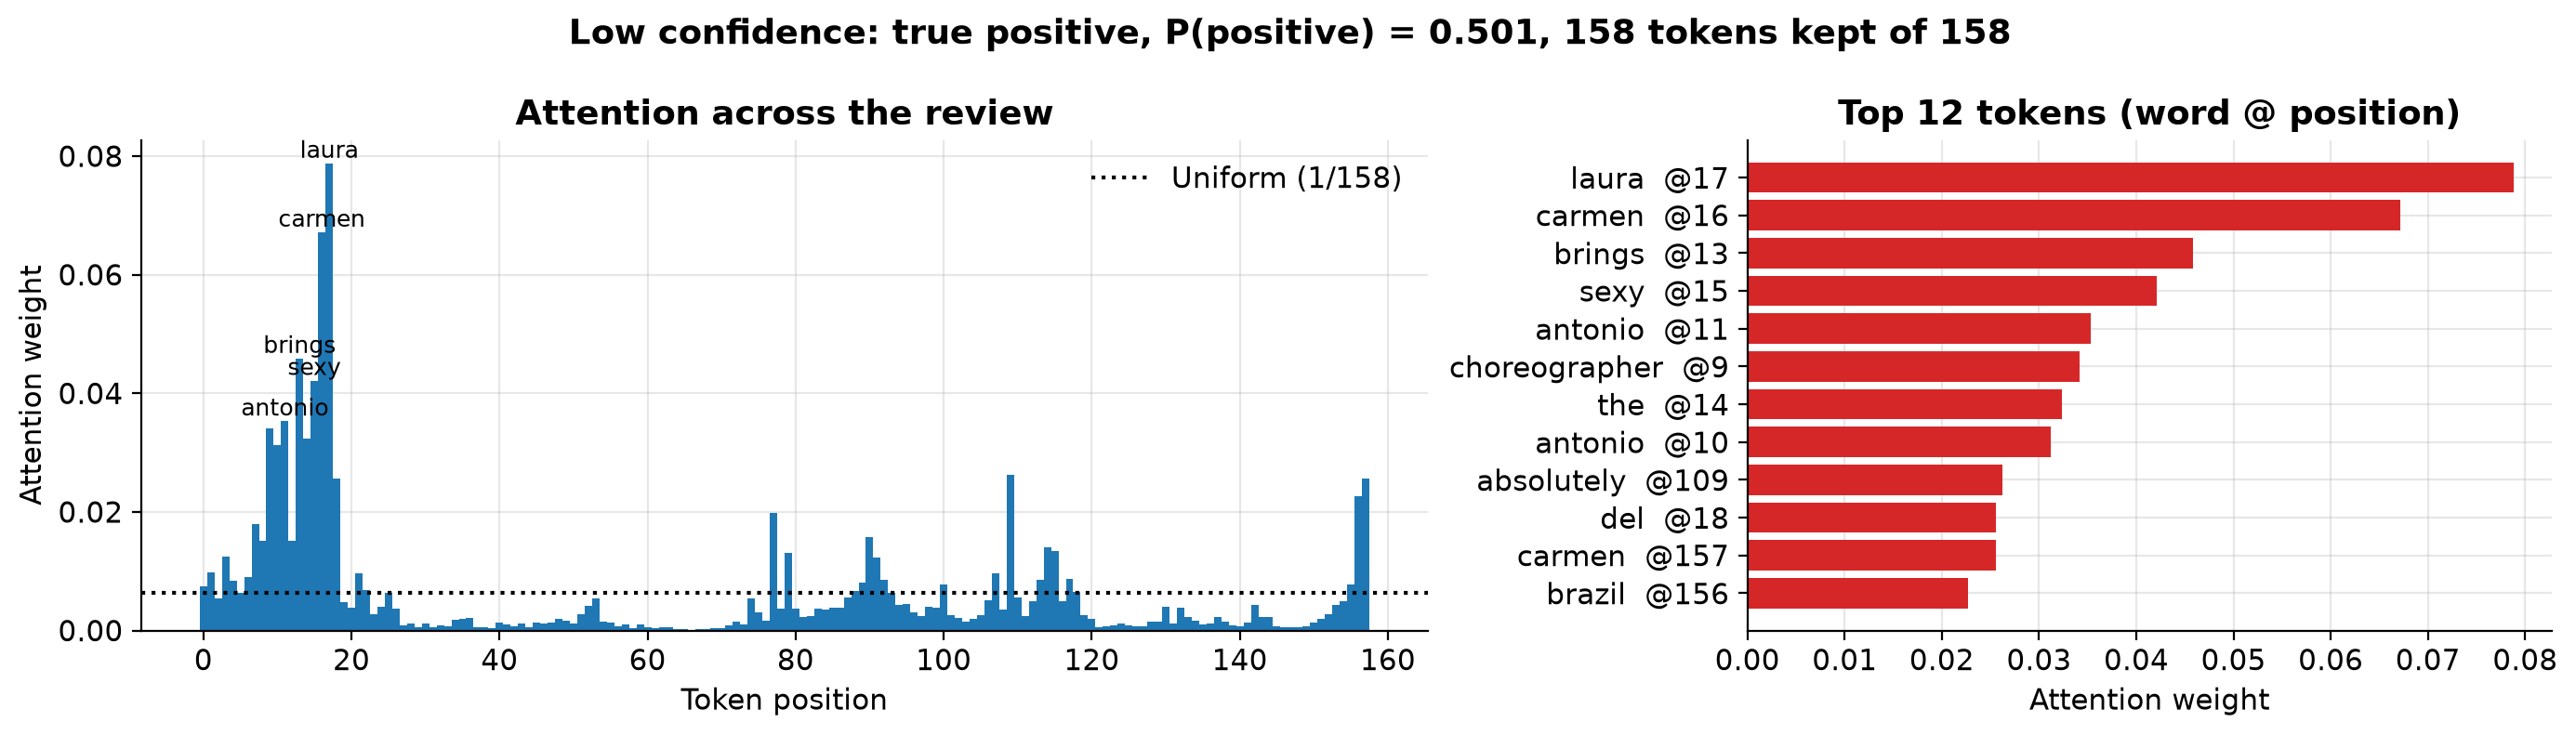

In [26]:
show_case("Low confidence", cases["Low confidence"])

,token,weight,× uniform
position,,,
93,excellent,0.0327,6.5463
149,amazing,0.0276,5.5106
6,masterpiece,0.0253,5.0676
143,masterpiece,0.0242,4.8425
103,terrifying,0.0209,4.1814
166,amazing,0.0195,3.8926
11,amazing,0.0184,3.6764
87,amazing,0.0180,3.6014
17,suspenseful,0.0166,3.3139


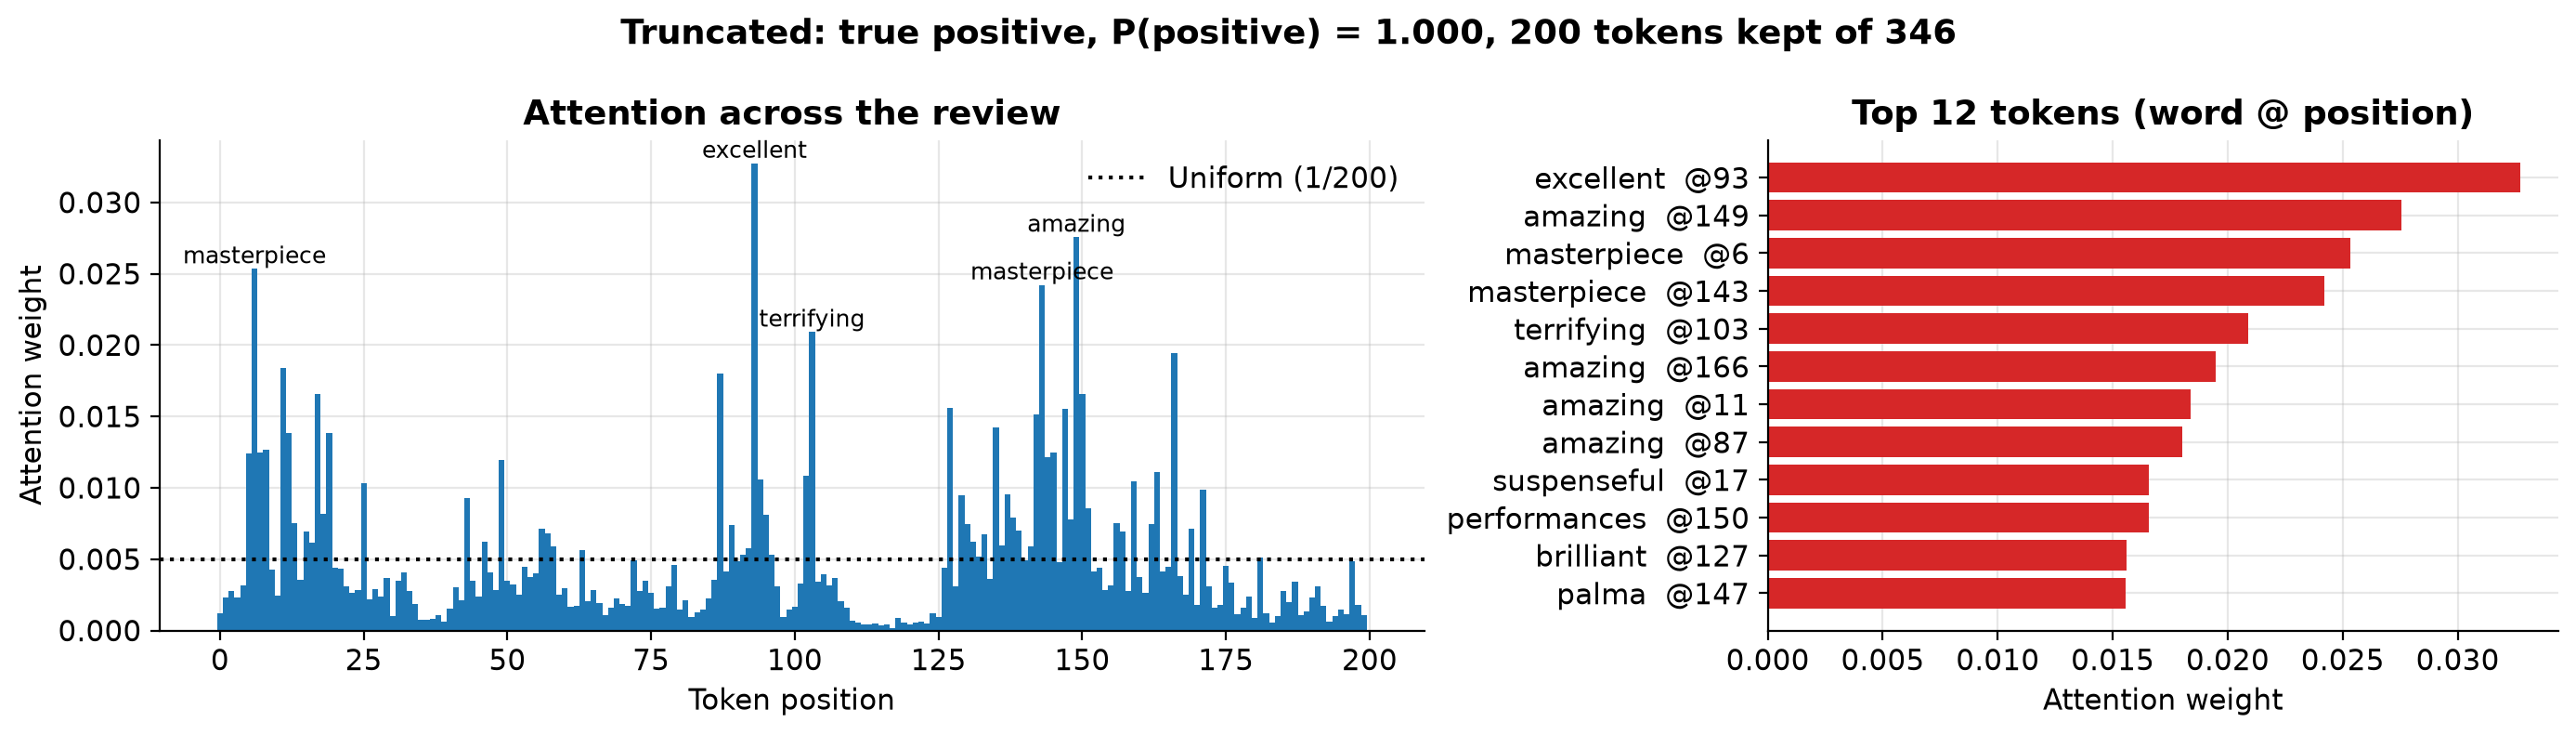

In [27]:
show_case("Truncated", cases["Truncated"])

### Attention across the whole validation set

Five reviews are anecdotes. Three aggregate views test whether they are typical:

- **Concentration:** for every validation review, the share of attention held by its top 5 tokens and the *effective number of attended tokens*, $\exp(-\sum_t \alpha_t \log \alpha_t)$, which equals $n$ for uniform attention over $n$ tokens and 1 when all mass sits on one token.
- **Most-attended words:** which tokens most often receive a review's single highest weight, and how much attention the non-words `<start>` and `<oov>` receive on average.
- **Position:** mean attention by relative position within the kept text, for reviews kept whole and for truncated reviews.

,mean,std,min,10%,50%,90%,max
tokens,161.268,44.982,13.000,96.000,179.000,200.000,200.000
top-5 share,0.256,0.084,0.085,0.167,0.241,0.362,0.855
effective tokens,78.345,25.501,7.236,43.655,79.298,110.866,156.836
effective / tokens,0.493,0.106,0.168,0.355,0.494,0.629,0.931
max weight,0.083,0.041,0.021,0.044,0.073,0.133,0.596


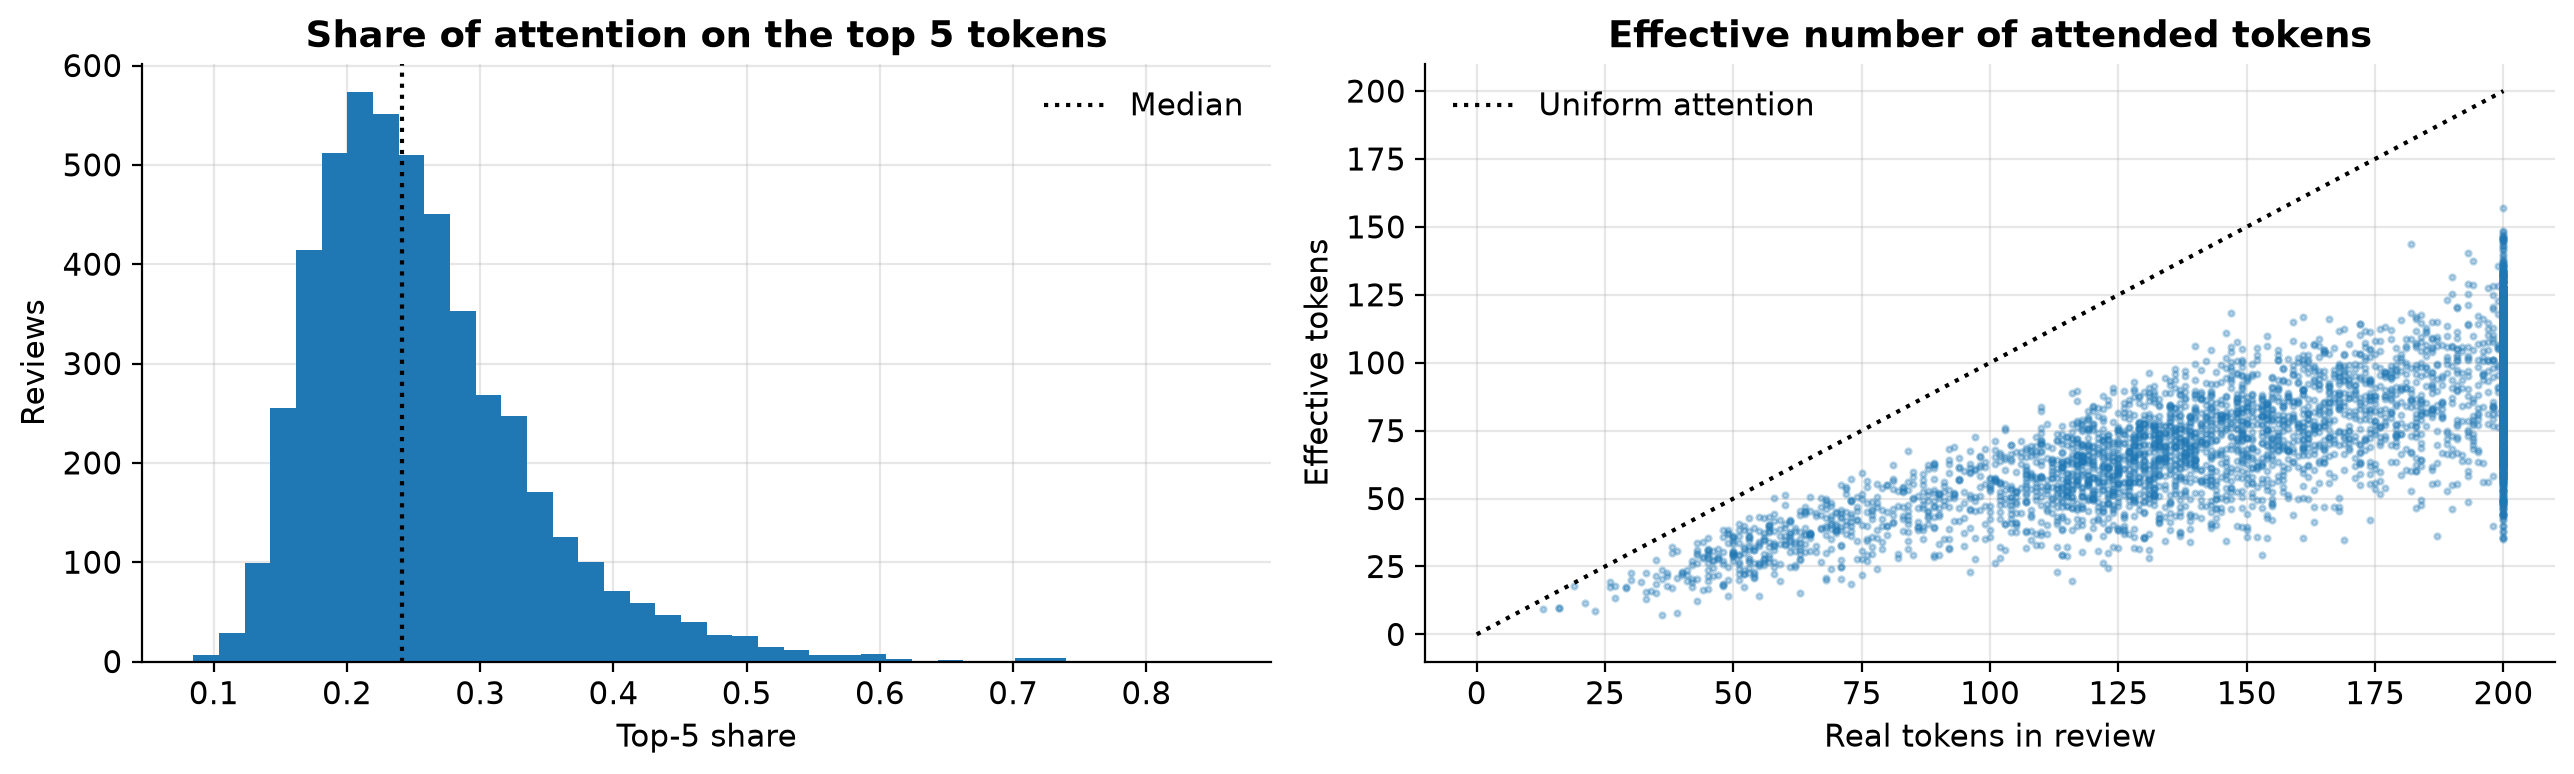

In [28]:
def concentration_stats() -> pd.DataFrame:
    """Per-review attention concentration over the real tokens of each validation review."""
    rows = []
    for i, n in enumerate(val_lengths):
        w = val_attention[i, :n]
        effective = np.exp(-np.sum(w * np.log(np.clip(w, 1e-12, None))))
        rows.append(
            {
                "tokens": n,
                "top-5 share": np.sort(w)[-5:].sum(),
                "effective tokens": effective,
                "effective / tokens": effective / n,
                "max weight": w.max(),
            }
        )
    return pd.DataFrame(rows)


concentration = concentration_stats()
display(concentration.describe(percentiles=[0.1, 0.5, 0.9]).T.drop(columns="count").round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(concentration["top-5 share"], bins=40)
ax1.axvline(concentration["top-5 share"].median(), color="k", ls=":", label="Median")
ax1.set(title="Share of attention on the top 5 tokens", xlabel="Top-5 share", ylabel="Reviews")
ax1.legend()
ax2.scatter(concentration["tokens"], concentration["effective tokens"], s=4, alpha=0.3)
ax2.plot([0, MAX_LEN], [0, MAX_LEN], "k:", label="Uniform attention")
ax2.set(
    title="Effective number of attended tokens",
    xlabel="Real tokens in review",
    ylabel="Effective tokens",
)
ax2.legend()
plt.tight_layout()
plt.show()

In [29]:
def most_attended_tokens(top_n: int = 20) -> pd.DataFrame:
    """Tokens that most often receive a review's single highest attention weight."""
    argmax_ids = np.array(
        [X_val[i, np.argmax(val_attention[i, :n])] for i, n in enumerate(val_lengths)]
    )
    counts = pd.Series(argmax_ids).value_counts().head(top_n)
    return pd.DataFrame(
        {
            "token": [index_to_word.get(int(t), "<oov>") for t in counts.index],
            "reviews where it is the top token": counts.values,
            "share of those predicted positive": [val_pred[argmax_ids == t].mean() for t in counts.index],
        }
    )


def special_token_attention() -> pd.Series:
    """Mean attention per review on <start> and <oov>, against their share of tokens."""
    oov = X_val == 2
    return pd.Series(
        {
            "Mean attention on <start>": val_attention[:, 0].mean(),
            "Mean total attention on <oov> tokens": np.where(oov, val_attention, 0).sum(axis=1).mean(),
            "Mean share of tokens that are <oov>": (oov.sum(axis=1) / val_lengths).mean(),
            "Uniform weight per token (mean 1/n)": (1 / val_lengths).mean(),
        }
    )


display(most_attended_tokens().round(3))
special_token_attention().round(4).to_frame("value")

,token,reviews where it is the top token,share of those predicted positive
0,this,170,0.182
1,worst,111,0.000
2,awful,79,0.025
3,excellent,77,0.961
4,wonderful,72,0.958
5,perfect,58,0.897
6,recommend,58,0.862
7,absolutely,56,0.214
8,film,55,0.273
9,fun,54,0.759


,value
Mean attention on <start>,0.0094
Mean total attention on <oov> tokens,0.0219
Mean share of tokens that are <oov>,0.0528
Uniform weight per token (mean 1/n),0.0072


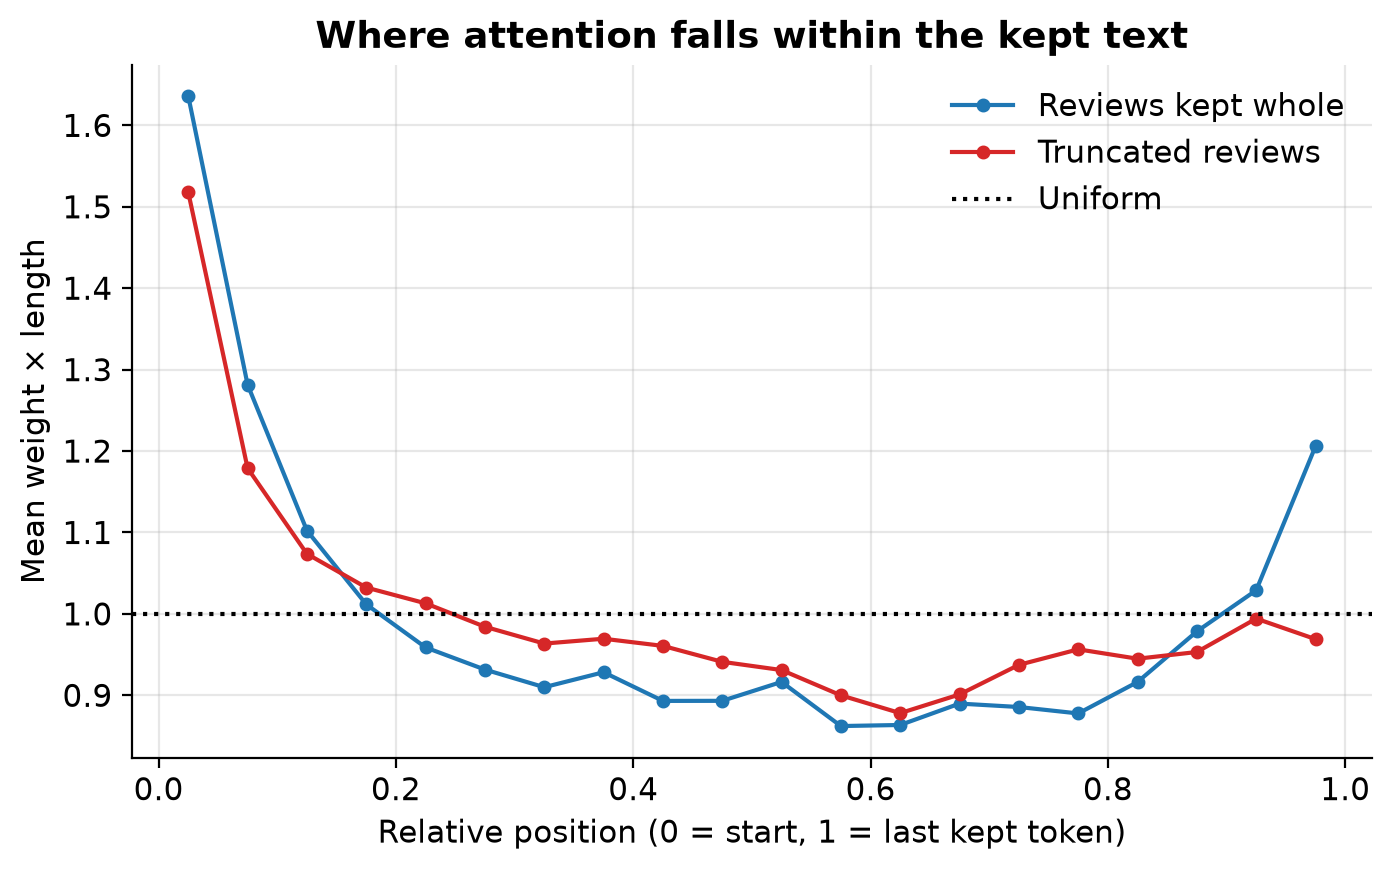

In [30]:
def attention_by_relative_position(lengths: np.ndarray, attention: np.ndarray, bins: int = 20) -> pd.Series:
    """Mean (weight × length) per relative-position bin; 1.0 = uniform attention."""
    sums, counts = np.zeros(bins), np.zeros(bins)
    for n, w in zip(lengths, attention):
        which = np.minimum((np.arange(n) / n * bins).astype(int), bins - 1)
        np.add.at(sums, which, w[:n] * n)
        np.add.at(counts, which, 1)
    return pd.Series(sums / counts, index=(np.arange(bins) + 0.5) / bins)


fig, ax = plt.subplots()
for label, pool, color in (
    ("Reviews kept whole", ~val_truncated, "C0"),
    ("Truncated reviews", val_truncated, "C3"),
):
    profile = attention_by_relative_position(val_lengths[pool], val_attention[pool])
    ax.plot(profile.index, profile.values, "-o", ms=4, color=color, label=label)
ax.axhline(1.0, color="k", ls=":", label="Uniform")
ax.set(
    title="Where attention falls within the kept text",
    xlabel="Relative position (0 = start, 1 = last kept token)",
    ylabel="Mean weight × length",
)
ax.legend()
plt.show()

### Do the weights track influence? A deletion test

A high attention weight is a statement about where the pooling layer looked, not about what changed the prediction. A direct check: for 500 random validation reviews, delete the 5 highest-weighted tokens and re-predict, and compare with deleting 5 randomly chosen real tokens (excluding `<start>`) from the same reviews. If attention identifies influential tokens, the first deletion should push predictions away from the predicted class, and flip them, more often than the second.

In [31]:
DELETE_K = 5
N_PROBE = 500


def delete_positions(row: np.ndarray, n: int, positions: np.ndarray) -> np.ndarray:
    """Remove the given positions from the first n tokens and re-pad to MAX_LEN."""
    kept = np.delete(row[:n], positions)
    return np.pad(kept, (0, MAX_LEN - len(kept)))


def deletion_test() -> pd.DataFrame:
    """Prediction change after deleting the top-k attended tokens vs k random tokens."""
    rng = np.random.default_rng(SEED)
    probe = rng.choice(np.flatnonzero(val_lengths > 2 * DELETE_K), size=N_PROBE, replace=False)
    top_rows, random_rows = [], []
    for i in probe:
        n = val_lengths[i]
        top = np.argsort(val_attention[i, :n])[-DELETE_K:]
        rand = rng.choice(np.arange(1, n), size=DELETE_K, replace=False)
        top_rows.append(delete_positions(X_val[i], n, top))
        random_rows.append(delete_positions(X_val[i], n, rand))
    original = val_probs[probe]
    toward_prediction = np.where(val_pred[probe] == 1, 1.0, -1.0)
    results = {}
    for name, rows in (("Top-5 attended deleted", top_rows), ("5 random deleted", random_rows)):
        new = attention_model.predict(np.stack(rows), batch_size=256, verbose=0).ravel()
        results[name] = {
            "Mean |Δ P(positive)|": np.mean(np.abs(new - original)),
            "Mean shift toward predicted class": np.mean((new - original) * toward_prediction),
            "Prediction flips (%)": 100 * np.mean((new >= THRESHOLD) != (original >= THRESHOLD)),
        }
    return pd.DataFrame(results).T


deletion_test().round(4)

,Mean |Δ P(positive)|,Mean shift toward predicted class,Prediction flips (%)
Top-5 attended deleted,0.1366,-0.1137,12.6
5 random deleted,0.0251,-0.0129,3.0


### Attention analysis

**Relevance.** In the two clear cases, the highest weights fall on sentiment. The correct negative (#3950, P(positive) = 0.0000) puts its top weights on *feeble* (0.174, 9.1× uniform), *dire*, *lifeless*, *turgid* and *avoid*, and on the nouns they describe (*characterization*, *script*, *dialogue*). The correct positive (#348, P = 1.0000) leads with *wonderfully* (0.155, 8.8×), *relaxed*, *cracking* and *recommend*, but also weights the names *vance*, *philo*, *powell* and *william*. These sit inside "the best of the philo vance series william powell looks wonderfully relaxed", so the weight on a name most likely reflects sentiment the BiLSTM carried there from "best" and "wonderfully". Across the whole validation set, the tokens that most often receive a review's highest weight are mostly sentiment words with consistent polarity: *worst* (111 reviews, 0% predicted positive), *awful* (2.5%), *excellent* (96.1%), *wonderful* (95.8%), *disappointment* (8.6%), and "8" as in 8/10 (90.9%).

**Concentrated or distributed.** Moderately concentrated. In the median review the top 5 tokens hold 24.1% of the attention, about 8.6 times their uniform share (5 of 179 tokens), while the effective number of attended tokens is about half the review (median ratio 0.494). The per-case bar charts match this pattern: a few spikes over a broad base. The truncated case is the flattest (top weight 0.033), with its weight spread over repeated praise (*amazing* four times in its top ten, *masterpiece* twice).

**Misleading or uninformative words.** The most frequent top token is the function word *this* (170 reviews, 82% of them predicted negative), and intensifiers such as *absolutely* and *truly* also rank high, although their polarity depends on context. A weight on these words can only reflect context the LSTM mixed into those positions ("avoid this", "absolutely awful"). The model does not over-attend to non-words: `<oov>` tokens are 5.3% of tokens but receive 2.2% of the attention (0.4× their share), `<start>` receives 1.3× a uniform weight, and `br` (the remnant of HTML line breaks) is not among the top 20 tokens. The incorrect case is the most informative. Review #2042 is labelled negative and predicted positive with P = 1.0000. Its largest weight by far is on *mildred* (0.236, 45.5× uniform), the word right after "bette davis did a wonderful job as"; other high weights fall on *job*, *wonderful*, *perfect* and *recommend*. The reviewer praises the acting throughout but calls the film "so so" and says it "wasn't the best". The attention map shows the decision was built on the praise of the acting while the weakly worded verdict was missed. The low-confidence case (#3479, P = 0.5013) is mostly plot summary: its top weights fall on character names and plot words near the start (*laura*, *carmen*, *antonio*, *choreographer*), and neither verdict sentence ("another great movie", "my vote is seven") is among the ten highest weights. Diffuse attention on non-evaluative text goes with an undecided prediction.

**Truncation and padding.** Padding cannot mislead: its weight is exactly 0 (printed above). Truncation can. The relative-position plot is U-shaped. For reviews kept whole, the first 5% of tokens get 1.63 times the uniform weight, the last 5% get 1.21 times, and the middle about 0.9. For truncated reviews the start is still high (1.52) but the end does not rise (0.97), because the last kept token is an arbitrary cut point, not the reviewer's conclusion. The truncated case (#1256) was classified correctly only because its first 200 tokens were already full of praise; the attention map says nothing about the 146 tokens the model never saw. The U shape also needs care. The hidden states at the two ends are where the backward and the forward LSTM have each read the whole review, so high weight there may reflect the model reusing those whole-review summaries, not the first and last words themselves.

**Deletion test.** Deleting each review's 5 highest-weighted tokens moves P(positive) by 0.137 on average, against 0.025 for 5 random tokens (5.4×). It flips 12.6% of predictions against 3.0% (4.2×), and it moves predictions away from the predicted class (−0.114). The weights therefore pick out tokens that matter far more than chance. Still, 87.4% of predictions survive losing their top 5 tokens, so in most reviews the evidence is spread out and redundant.

**Why attention weights are not causal explanations.** An attention weight $\alpha_t$ says how much hidden state $h_t$ contributes to the average $c$; it does not say that the *word* at position $t$ caused the prediction. Three gaps separate the two. First, $h_t$ is not the word: it is the output of a bidirectional LSTM that has already mixed in information from every other token, so a high weight on "film" may reflect sentiment the LSTM carried there from "boring" ten words earlier. Second, a weight is only one factor of a position's contribution: the head acts on $\alpha_t h_t$, so a position with a large weight but a hidden state the head barely responds to contributes little, while many small weights can add up. Third, attention distributions are not unique: different weight patterns can produce nearly the same context vector and prediction, and Jain and Wallace (2019) show that adversarially constructed attention distributions can differ sharply from the learned ones without changing the output. Causal claims require interventions, such as the deletion test above, and even that only shows the effect of removing a token in this particular context. Wiegreffe and Pinter (2019) argue attention can still serve as *an* explanation when checked this way; it is evidence to be tested, not a verdict.

## Step 6 — Compare the models

**Reporting rule.** For both models: trainable parameters are counted from the model's weights; best validation accuracy is the maximum validation accuracy over the epochs of the run, which is also the epoch whose weights early stopping restored. **Selection rule, fixed before any test data are used:** the model with the higher best validation accuracy is selected; on an exact tie, the model with fewer parameters.

In [32]:
def key_observation(run: Run) -> str:
    """One-line, number-backed observation drawn from the run summary."""
    s = summarize(run)
    return (
        f"best at epoch {s['Best epoch']} of {s['Epochs run']}; "
        f"train−val gap {s['Accuracy gap (train − val)']:.3f}; "
        f"lowest val loss at epoch {s['Epoch of lowest val loss']}; "
        f"{s['Mean s / epoch (after epoch 1)']:.0f} s/epoch"
    )


summary_table = pd.DataFrame(
    [
        {
            "Model": name,
            "Trainable parameters": parameter_counts(run.model)[1],
            "Best validation accuracy": summarize(run)["Best val accuracy"],
            "Key observation": key_observation(run),
        }
        for name, run in runs.items()
    ]
).set_index("Model")

selected_name = max(
    runs,
    key=lambda name: (
        summary_table.loc[name, "Best validation accuracy"],
        -summary_table.loc[name, "Trainable parameters"],
    ),
)
display(
    summary_table.style.format(
        {"Trainable parameters": "{:,}", "Best validation accuracy": "{:.4f}"}
    )
)
print(f"Selected on validation evidence: {selected_name}")

,Trainable parameters,Best validation accuracy,Key observation
Model,,,
Final-state BiLSTM,"1,387,137",0.8548,best at epoch 3 of 6; train−val gap 0.074; lowest val loss at epoch 1; 4 s/epoch
Attention-based BiLSTM,"1,395,457",0.8514,best at epoch 4 of 7; train−val gap 0.096; lowest val loss at epoch 1; 4 s/epoch


Selected on validation evidence: Final-state BiLSTM


### Model selection

The rule selects the **final-state BiLSTM**: its best validation accuracy (0.8548) is 0.34 points, or 17 of 5,000 reviews, above the attention model's (0.8514). The margin is smaller than the roughly 0.5-point sampling error of either estimate, and the execution on a different GPU node reversed it (0.8380 vs 0.8522). The selection is therefore a tie broken by the pre-set rule, not evidence that final states are better. On accuracy, the attention layer's cost (8,320 parameters, or 0.6%, and about 0.3 s, or 7%, more per epoch) is neither justified nor ruled out. It is justified by interpretive value. The per-token weights diagnosed the confident error (praise of the acting outweighing a lukewarm verdict), showed that the model relies on review endings and loses that signal when a review is truncated, and passed a deletion check (4.2 times more flips than random). Those weights are evidence of where the model looks, not proof of why it decides (Step 5). Where interpretability matters, the attention model is a reasonable choice at no measurable accuracy cost. The test evaluation below follows the rule as fixed in advance.

## Step 7 — Evaluate the final model

The selected model, with its best-validation-epoch weights, is evaluated **once** on the 25,000 held-out test reviews at threshold 0.5. Nothing below feeds back into selection.

In [33]:
final_run = runs[selected_name]
final_model = final_run.model
final_summary = summarize(final_run)

test_loss, test_accuracy_keras = final_model.evaluate(X_test, y_test, batch_size=256, verbose=0)
test_probs = final_model.predict(X_test, batch_size=256, verbose=0).ravel()
test_pred = (test_probs >= THRESHOLD).astype(int)

total_params, trainable_params = parameter_counts(final_model)
final_report = pd.Series(
    {
        "Selected model": selected_name,
        "Architecture": " → ".join(layer.name for layer in final_model.layers if layer.weights),
        "Best validation accuracy": (
            f"{final_summary['Best val accuracy']:.4f} (epoch {final_summary['Best epoch']})"
        ),
        "Test loss (binary cross-entropy)": f"{test_loss:.4f}",
        "Test accuracy": f"{accuracy_score(y_test, test_pred):.4f}",
        "Precision (positive class)": f"{precision_score(y_test, test_pred):.4f}",
        "Recall (positive class)": f"{recall_score(y_test, test_pred):.4f}",
        "F1-score (positive class)": f"{f1_score(y_test, test_pred):.4f}",
        "Total parameters": f"{total_params:,}",
        "Trainable parameters": f"{trainable_params:,}",
    },
    name="Value",
)
print(f"Keras-reported test accuracy (cross-check): {test_accuracy_keras:.4f}")
final_report.to_frame()

Keras-reported test accuracy (cross-check): 0.8446


,Value
Selected model,Final-state BiLSTM
Architecture,embedding → bilstm → head_dense → output
Best validation accuracy,0.8548 (epoch 3)
Test loss (binary cross-entropy),0.4694
Test accuracy,0.8446
Precision (positive class),0.8424
Recall (positive class),0.8478
F1-score (positive class),0.8451
Total parameters,"1,387,137"
Trainable parameters,"1,387,137"


              precision    recall  f1-score   support

    negative     0.8468    0.8414    0.8441     12500
    positive     0.8424    0.8478    0.8451     12500

    accuracy                         0.8446     25000
   macro avg     0.8446    0.8446    0.8446     25000
weighted avg     0.8446    0.8446    0.8446     25000



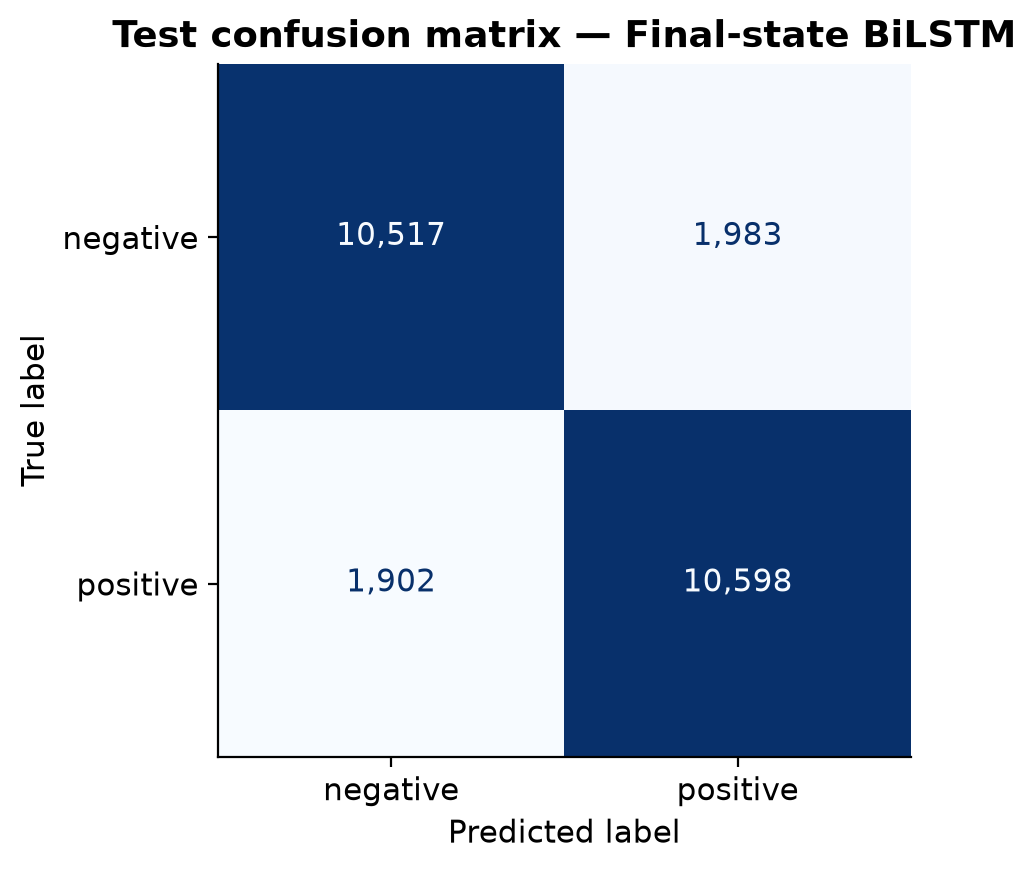

In [34]:
print(classification_report(y_test, test_pred, target_names=["negative", "positive"], digits=4))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_pred), display_labels=["negative", "positive"]
).plot(ax=ax, cmap="Blues", values_format=",", colorbar=False)
ax.set(title=f"Test confusion matrix — {selected_name}", xlabel="Predicted label", ylabel="True label")
ax.grid(False)
plt.show()

### Beyond overall accuracy

Two breakdowns of the same test predictions: accuracy by whether the review was truncated, and how often the model is confidently wrong.

,Reviews,Accuracy
≤ 200 tokens (kept whole),14732,0.8779
> 200 tokens (truncated),10268,0.7968


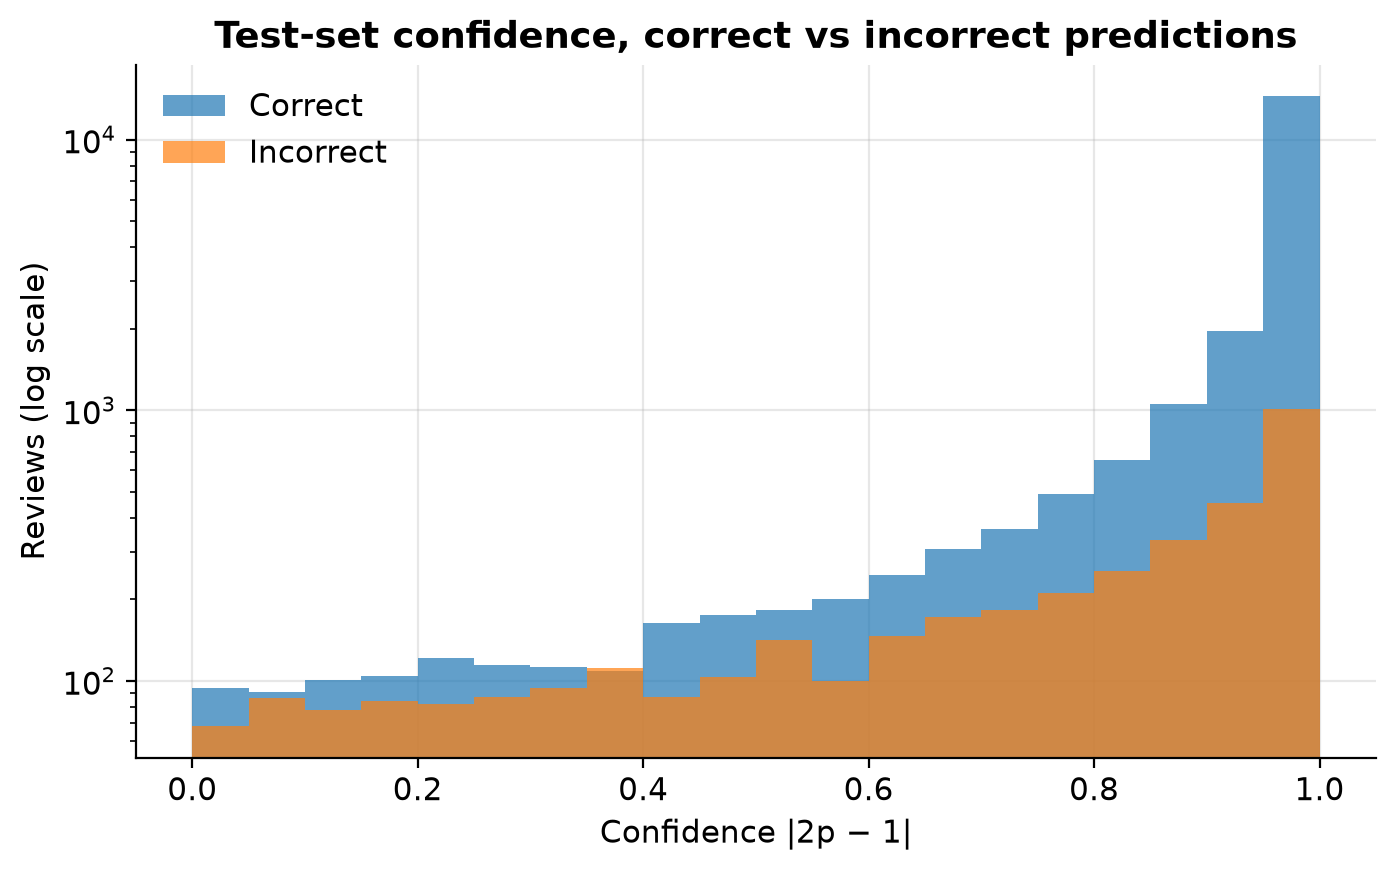

Errors made with confidence ≥ 0.8: 52.8% of all errors


In [35]:
test_truncated = test_raw_lengths > MAX_LEN
test_confidence = np.abs(test_probs - 0.5) * 2  # 0 = at the threshold, 1 = certain

breakdown = pd.DataFrame(
    {
        "Reviews": [int((~test_truncated).sum()), int(test_truncated.sum())],
        "Accuracy": [
            accuracy_score(y_test[~test_truncated], test_pred[~test_truncated]),
            accuracy_score(y_test[test_truncated], test_pred[test_truncated]),
        ],
    },
    index=[f"≤ {MAX_LEN} tokens (kept whole)", f"> {MAX_LEN} tokens (truncated)"],
)
display(breakdown.round(4))

errors = test_pred != y_test
fig, ax = plt.subplots()
bins = np.linspace(0, 1, 21)
ax.hist(test_confidence[~errors], bins=bins, alpha=0.7, label="Correct")
ax.hist(test_confidence[errors], bins=bins, alpha=0.7, label="Incorrect")
ax.set(
    title="Test-set confidence, correct vs incorrect predictions",
    xlabel="Confidence |2p − 1|",
    ylabel="Reviews (log scale)",
    yscale="log",
)
ax.legend()
plt.show()
print(f"Errors made with confidence ≥ 0.8: {np.mean(test_confidence[errors] >= 0.8):.1%} of all errors")

### Test-set interpretation

**Test versus validation.** Test accuracy is 0.8446, 1.0 point below the best validation accuracy (0.8548), and test loss is 0.4694 against 0.4549 at the best validation epoch. A drop of this size is expected. The validation score is a maximum over epochs and over models, so it is optimistically biased. The 5,000 validation reviews also carry about ±0.5 points of sampling error, against about ±0.23 points for the 25,000 test reviews, so the test figure is the more reliable estimate.

**Error balance.** Errors are balanced: 1,983 false positives and 1,902 false negatives. Positive-class precision (0.8424) and recall (0.8478) differ by half a point, and the two per-class F1 scores are 0.8441 (negative) and 0.8451 (positive). The model predicts "positive" for 12,581 of 25,000 reviews, almost exactly the true 50%. Overall accuracy does not hide a weakness on one class.

**Truncation.** Accuracy is 0.8779 on the 14,732 reviews kept whole but 0.7968 on the 10,268 truncated ones, a gap of 8.1 points. This fits the view that the 200-token limit costs accuracy: a truncated review loses its ending, which is often where the verdict is, and the attention model's position profile (Step 5) puts extra weight on endings. The gap is not purely a truncation effect, though. Long reviews may be harder in themselves (more plot summary, more mixed opinions), and this split cannot separate the two causes. Measuring the cost of truncation directly would need a run with a longer `MAX_LEN`.

**Confidence.** Confidence is informative but not reliable enough on its own. Below a confidence of about 0.4, correct and incorrect predictions occur in similar numbers, so those predictions are close to coin flips. Yet 52.8% of all errors are made with confidence of at least 0.8, and the most confident bin alone holds about a thousand errors. This overconfidence matches the training curves: by the selected epoch, validation loss had already risen above its epoch-1 minimum. A confidence threshold would flag only a minority of the mistakes.

These results are reported only; the model is not revised or reselected on them.

## Final analysis and reflection

### Question 1 — How did the two models differ in how they selected and summarized information, and in training behavior and validation performance?

**How they selected and summarized information.** Both models read each review with the same masked embedding and the same 64-unit BiLSTM, starting from identical weights. They differ only in how they turn the hidden states into one vector. The baseline keeps two: the forward state after the last kept token and the backward state at the first token. Everything the classifier uses must survive the LSTM's step-by-step compression into those two 64-dimensional vectors, and nothing shows which tokens mattered. The attention model scores every hidden state with $e_t = v^\top \tanh(W^\top h_t + b)$, normalises the scores over real tokens only, and passes the weighted average $c = \sum_t \alpha_t h_t$ to the same head, so any position can contribute directly. In practice it did not pick out just a few words. In the median review it spread its weight over about half of the tokens (effective-token ratio 0.494), with the top 5 tokens holding 24%. It also gave extra weight to the two ends of each review, where the BiLSTM's whole-review summaries sit. The attention model can therefore approximate the baseline's final-state summary and add selected words from the middle of the review on top of it.

**Training behavior and validation performance.** The two runs behaved much more alike than the difference in mechanism suggests. Both reach about 0.834 validation accuracy after one epoch, and both have their lowest validation loss right then (0.3835 baseline, 0.3733 attention). Both overfit afterwards: training accuracy passes 0.97 while validation loss nearly doubles. The baseline peaked at **0.8548 (epoch 3)** with a 7.4-point train − validation gap; the attention model peaked at **0.8514 (epoch 4)** with a 9.6-point gap. Attention's validation curve rose more smoothly to its peak but fell faster afterwards (5.6 points by epoch 7). The 0.34-point difference in best validation accuracy is smaller than the sampling error (about 0.5 points), and an execution on different GPU hardware reversed it (0.8380 vs 0.8522), so the evidence supports equal accuracy within noise, not a winner. The costs are also close: 8,320 extra parameters (0.6%) and about 0.3 s (7%) more per epoch on an L40S. The selection rule chose the baseline, which scored 0.8446 on the held-out test set with balanced errors. Its accuracy fell from 0.878 on whole reviews to 0.797 on truncated ones. That gap suggests how much of a review the model sees may matter more than how it summarises it, although review length is confounded with difficulty.

### Question 2 — What useful information did the attention weights provide, and why are they not definitive explanations of individual predictions?

**What the attention weights showed.** The weights gave three kinds of useful information. First, they confirmed that the model attends to sentiment. Across the validation set the most frequent top tokens were words like *worst*, *awful*, *excellent* and *wonderful*, each strongly tied to one predicted class, and in the clear negative example *feeble*, *dire* and *lifeless* took the largest weights. Second, they helped diagnose failures. In the confidently wrong review (#2042), the model put 45 times the uniform weight on the word right after "did a wonderful job as" and leaned on praise of the acting, while the reviewer's verdict ("so so") went unnoticed. In the low-confidence review (#3479), weight spread over plot summary, and neither verdict sentence was among the top tokens. Third, the aggregate views revealed habits no single example shows: a U-shaped preference for the start and end of a review, an end peak that disappears when the review is truncated, and weights on `<oov>` well below their share of tokens. The deletion test showed the weights are not arbitrary: removing the 5 most-attended tokens flipped 12.6% of predictions, against 3.0% for 5 random tokens.

**Why they are not definitive explanations.** Each of those observations also shows a limit. First, the weights attach to hidden states, not words. The heavy weight on *mildred* and *vance*, and the frequent top token *this*, make sense only if the BiLSTM carried neighbouring sentiment into those positions; the weight points to a position whose meaning comes from its context. Second, a weight is only one factor in a position's contribution, since the head acts on $\alpha_t h_t$. In the truncated review the decision rested on many small weights (none above 0.033) spread over repeated praise. Third, attention is not unique: different weight patterns can produce nearly the same context vector (Jain & Wallace, 2019), and the U shape may mean the model is reusing whole-review summary states rather than reading the first and last words. Fourth, only an intervention tests influence, and ours is limited. Deleting the top 5 tokens left 87.4% of predictions unchanged, deletion creates text unlike anything seen in training, and attention was compared only with random deletion, not with other attribution methods. Attention weights are therefore a useful, testable hint about where the model looks, not a causal account of why it made a particular prediction (Wiegreffe & Pinter, 2019).

## References

Bahdanau, D., Cho, K., & Bengio, Y. (2015). Neural machine translation by jointly learning to align and translate. *International Conference on Learning Representations*. https://arxiv.org/abs/1409.0473

Chollet, F. (2021). *Deep learning with Python* (2nd ed.). Manning Publications.

Jain, S., & Wallace, B. C. (2019). Attention is not explanation. *Proceedings of the 2019 Conference of the North American Chapter of the Association for Computational Linguistics*, 3543–3556. https://doi.org/10.18653/v1/N19-1357

Maas, A. L., Daly, R. E., Pham, P. T., Huang, D., Ng, A. Y., & Potts, C. (2011). Learning word vectors for sentiment analysis. *Proceedings of the 49th Annual Meeting of the Association for Computational Linguistics*, 142–150. https://aclanthology.org/P11-1015

Wiegreffe, S., & Pinter, Y. (2019). Attention is not not explanation. *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing*, 11–20. https://doi.org/10.18653/v1/D19-1002

The `AdditiveAttentionPooling` class structure (`__init__` and `build`) follows the starter code in the Assignment 5 brief. The dataset is loaded through `keras.datasets.imdb`.